<a href="https://colab.research.google.com/github/artrai73/CardioSense/blob/main/02_ecg_training_new_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CardioSense Phase 1 — Pipeline 2: ECG Interpretation

**PTB-XL → signal preprocessing → statistical baseline → 1D CNN → Integrated Gradients**

Run `00_colab_setup.ipynb` first, including section 7b (the PTB-XL download).

**This notebook needs a GPU.** `Runtime → Change runtime type → GPU`.

### Sections
1. Environment Setup · 2. Imports · 3. Configuration · 4. Dataset Verification
5. Exploratory Data Analysis · 6. Preprocessing · 7. Dataset Splitting · 8. Baseline
9. Model Definition · 10. Training · 11. Validation · 12. Evaluation
13. Explainability · 14. *(calibration — see note)* · 15. Error Analysis
16. Save Model · 17. Save Results · 18. Example Inference

### The task, stated precisely

**5-class diagnostic superclass classification — MULTI-LABEL.**

`NORM`, `MI`, `STTC`, `CD`, `HYP`. A single ECG can legitimately carry several of
these at once, so this is five independent binary decisions, not a choice among
five options. Everything downstream follows from that:

| Consequence | Why |
|---|---|
| `BCEWithLogitsLoss`, not cross-entropy | Softmax would force the five scores to compete for one probability budget |
| One threshold **per class** | Prevalence runs from ~12% (HYP) to ~44% (NORM) |
| **Accuracy is never reported** | Undefined for multi-label; exact-match ratio is reported under that name |
| Macro ROC-AUC is the headline | Weights all five classes equally, so rare classes cannot be hidden |

### Experiments
| ID | Experiment | Question |
|---|---|---|
| E-A | Statistical features + one-vs-rest LogReg | What floor must deep learning clear? |
| E-B | 1D CNN | Does temporal structure help beyond global statistics? |
| E-C | ResNet-1D *(optional)* | Does extra depth earn its cost? |

**On disconnects:** every epoch writes `last.pt`. If Colab drops, just re-run the
training cell — it resumes from the next epoch, it does not restart.

In [45]:
print(test_metrics)
print("\n**Per-Class Metrics:**")
per_class

{'macro_roc_auc': 0.9065910230874998, 'macro_pr_auc': 0.7741335438598307, 'macro_f1': 0.7091258040657537, 'micro_f1': 0.7511896668932699, 'weighted_f1': 0.7552461621265816, 'macro_precision': 0.681569400350789, 'macro_recall': 0.7463199399974803, 'hamming_loss': 0.13568118628359593, 'exact_match': 0.5639481000926784, 'n_samples': 2158, 'per_class': {'NORM': {'support': 963, 'prevalence': 0.4462465245597776, 'precision': 0.7919282511210762, 'recall': 0.9169262720664589, 'f1': 0.8498556304138595, 'threshold': 0.6502010050251257, 'roc_auc': 0.9388782439812824, 'pr_auc': 0.9153708811800098, 'roc_auc_ci': {'point': 0.9388782439812824, 'lower': 0.9299248330082284, 'upper': 0.9478064272362969, 'std': 0.004706064809142629}, 'pr_auc_ci': {'point': 0.9153708811800098, 'lower': 0.899434062708516, 'upper': 0.9303011285940982, 'std': 0.007783722470068094}}, 'MI': {'support': 550, 'prevalence': 0.2548656163113994, 'precision': 0.7013422818791947, 'recall': 0.76, 'f1': 0.7294938917975567, 'threshold'

,class,support,prevalence,threshold,roc_auc,pr_auc,precision,recall,f1,roc_auc_95ci
0,NORM,963,0.4462,0.650201,0.9389,0.9154,0.7919,0.9169,0.8499,"[0.930, 0.948]"
1,MI,550,0.2549,0.487688,0.9114,0.8092,0.7013,0.7600,0.7295,"[0.898, 0.924]"
2,STTC,521,0.2414,0.507387,0.9336,0.8238,0.7413,0.7754,0.7580,"[0.922, 0.945]"
3,CD,496,0.2298,0.714221,0.9217,0.8432,0.7947,0.7258,0.7587,"[0.907, 0.936]"
4,HYP,262,0.1214,0.453216,0.8275,0.4790,0.3786,0.5534,0.4496,"[0.801, 0.852]"


## 1. Environment Setup

In [1]:
from pathlib import Path
import os
import subprocess
import sys

REPO_DIR = Path("/content/CardioSense")

# Clone repository if this Colab runtime does not have it
if not REPO_DIR.exists():
    print("CardioSense repo not found. Cloning...")
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/artrai73/cardiosense.git",
            str(REPO_DIR)
        ],
        check=True
    )

os.chdir(REPO_DIR)

# Point the project to your existing Drive data
os.environ["CARDIOSENSE_DATA_ROOT"] = \
    "/content/drive/MyDrive/CardioSense/data"

# Install the project
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-e", "."],
    check=True
)

print("Repo:", REPO_DIR)
print("Working directory:", Path.cwd())
print("Data root:", os.environ["CARDIOSENSE_DATA_ROOT"])

CardioSense repo not found. Cloning...
Repo: /content/CardioSense
Working directory: /content/CardioSense
Data root: /content/drive/MyDrive/CardioSense/data


In [2]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)

    REPO_DIR = Path("/content/CardioSense")
    if not REPO_DIR.exists():
        raise RuntimeError("Repo not found. Run 00_colab_setup.ipynb first.")
    os.chdir(REPO_DIR)

    os.environ["CARDIOSENSE_DATA_ROOT"] = "/content/drive/MyDrive/CardioSense/data"

    subprocess.run(
        ["pip", "install", "-q", "-r", "requirements-colab.txt"],
        check=False
    )
    subprocess.run(
        ["pip", "install", "-q", "-e", "."],
        check=False
    )

else:
    here = Path.cwd()
    while not (here / "pyproject.toml").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

print("Working directory:", Path.cwd())
print("Data root        :", os.environ.get("CARDIOSENSE_DATA_ROOT"))

Mounted at /content/drive
Working directory: /content/CardioSense
Data root        : /content/drive/MyDrive/CardioSense/data


## 2. Imports

In [3]:
import sys
from pathlib import Path

SRC = Path("/content/CardioSense/src")

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("Added to Python path:")
print(SRC)

import cardiosense

print("\nCardioSense imported successfully!")
print("Location:", cardiosense.__file__)

Added to Python path:
/content/CardioSense/src

CardioSense imported successfully!
Location: /content/CardioSense/src/cardiosense/__init__.py


In [4]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

from cardiosense.common.config import load_config
from cardiosense.common.env import get_device, print_environment
from cardiosense.common.experiment import ExperimentTracker, load_experiment_log
from cardiosense.common.io_utils import save_json, save_pickle
from cardiosense.common.paths import PATHS
from cardiosense.common.plots import plot_class_distribution, plot_training_curves
from cardiosense.common.seeding import set_seed
from cardiosense.common.training import count_parameters

from cardiosense.ecg.data import (
    build_superclass_labels, describe_dataset, load_metadata,
    parse_scp_codes, resolve_ptbxl_root, split_by_fold, verify_dataset,
)
from cardiosense.ecg.preprocessing import (
    build_waveform_cache, load_raw_record, preprocess_signal, remove_baseline_wander,
)
from cardiosense.ecg.dataset import build_dataloaders, compute_pos_weight
from cardiosense.ecg.baseline import extract_feature_matrix, feature_names, train_baseline
from cardiosense.ecg.models import build_model, model_summary
from cardiosense.ecg.trainer import train_model
from cardiosense.ecg import evaluate as ev
from cardiosense.ecg.explain import run_ig_analysis
from cardiosense.ecg.predict import ECGPredictor

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)
_ = print_environment()

CARDIOSENSE RUNTIME ENVIRONMENT
  Python      : 3.13.15
  Platform    : Linux-6.6.122+-x86_64-with-glibc2.39
  CPU cores   : 2
  Colab       : True
  Git commit  : 77028d7
  GPU         : Tesla T4 (14.56 GB, sm_75)
  CUDA        : 12.8
  Packages    :
      captum         0.9.0
      numpy          2.1.3
      pandas         2.2.3
      scipy          1.16.3
      shap           0.52.0
      sklearn        1.6.1
      torch          2.11.0+cu128
      torchvision    0.26.0+cu128
      wfdb           4.3.1
      xgboost        3.4.1


## 3. Configuration

Everything comes from `configs/ecg_config.yaml`. Note `sampling_rate: 100` — PTB-XL
ships every record at both 100 Hz and 500 Hz, and we read the native 100 Hz files
rather than downsampling, so no resampling artefacts are introduced.

In [5]:
cfg = load_config("ecg")

SEED = int(cfg.seed)
set_seed(SEED, strict=bool(cfg.get("strict_determinism", False)))
device = get_device()

RESULTS = PATHS.root / cfg.output.results_dir
MODELS = PATHS.root / cfg.output.models_dir
CHECKPOINTS = MODELS / "checkpoints"
for path in (RESULTS, MODELS, CHECKPOINTS):
    path.mkdir(parents=True, exist_ok=True)

CLASSES = list(cfg.task.classes)

print(f"task          : {cfg.task.name} ({cfg.task.type})")
print(f"classes       : {CLASSES}")
print(f"sampling rate : {cfg.dataset.sampling_rate} Hz, {cfg.dataset.signal_length} samples "
      f"({cfg.dataset.signal_length / cfg.dataset.sampling_rate:.0f} s), "
      f"{cfg.dataset.n_leads} leads")
print(f"split         : folds {cfg.split.train_folds} / {cfg.split.val_folds} / "
      f"{cfg.split.test_folds}")
print(f"model         : {cfg.model.name} | batch {cfg.training.batch_size} | "
      f"lr {cfg.training.learning_rate} | epochs {cfg.training.epochs}")
print(f"device        : {device}")

[seed] seed=42 mode=seeded (cudnn.benchmark on)
[env] device: cuda
[env] gpu   : Tesla T4
[env] memory: 14.56 GB
[env] cuda  : 12.8 | capability sm_75
task          : diagnostic_superclass (multilabel)
classes       : ['NORM', 'MI', 'STTC', 'CD', 'HYP']
sampling rate : 100 Hz, 1000 samples (10 s), 12 leads
split         : folds [1, 2, 3, 4, 5, 6, 7, 8] / [9] / [10]
model         : cnn1d | batch 128 | lr 0.001 | epochs 40
device        : cuda


In [6]:
# ============================================================
# ECG CHECKPOINT SYSTEM
# ============================================================

from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd
import torch

DRIVE_ECG = Path("/content/drive/MyDrive/CardioSense")

DRIVE_ECG_MODELS = DRIVE_ECG / "models" / "ecg"
DRIVE_ECG_RESULTS = DRIVE_ECG / "results" / "ecg"
DRIVE_ECG_CHECKPOINTS = DRIVE_ECG_MODELS / "checkpoints"

for p in [
    DRIVE_ECG_MODELS,
    DRIVE_ECG_RESULTS,
    DRIVE_ECG_CHECKPOINTS,
]:
    p.mkdir(parents=True, exist_ok=True)

print("ECG checkpoint system ready")
print("Models :", DRIVE_ECG_MODELS)
print("Results:", DRIVE_ECG_RESULTS)

ECG checkpoint system ready
Models : /content/drive/MyDrive/CardioSense/models/ecg
Results: /content/drive/MyDrive/CardioSense/results/ecg


## 4. Dataset Verification

PTB-XL is open access — no credentialing form. If this cell fails, run section 7b
of `00_colab_setup.ipynb`.

In [7]:
root = resolve_ptbxl_root(cfg)
print(json.dumps(verify_dataset(cfg, root), indent=2))

database, statements = load_metadata(cfg, root)
print(f"\nrecords : {len(database)}")
print(f"patients: {database.patient_id.nunique()}")
print(f"folds   : {sorted(database.strat_fold.unique())}")
database[["patient_id", "age", "sex", "scp_codes", "strat_fold", "filename_lr"]].head()

2026-09-29 09:28:35 | INFO     | cardiosense.ecg.data         | PTB-XL verified at /content/drive/MyDrive/CardioSense/data/ecg/ptbxl (22 record folders at 100 Hz)
{
  "root": "/content/drive/MyDrive/CardioSense/data/ecg/ptbxl",
  "sampling_rate": 100,
  "database_csv": "/content/drive/MyDrive/CardioSense/data/ecg/ptbxl/ptbxl_database.csv",
  "record_folders": 22
}
2026-09-29 09:28:37 | INFO     | cardiosense.ecg.data         | Loaded metadata: 21799 records, 18869 patients, 71 SCP statements

records : 21799
patients: 18869
folds   : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


,patient_id,age,sex,scp_codes,strat_fold,filename_lr
ecg_id,,,,,,
1,15709.0,56.0,1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",3,records100/00000/00001_lr
2,13243.0,19.0,0,"{'NORM': 80.0, 'SBRAD': 0.0}",2,records100/00000/00002_lr
3,20372.0,37.0,1,"{'NORM': 100.0, 'SR': 0.0}",5,records100/00000/00003_lr
4,17014.0,24.0,0,"{'NORM': 100.0, 'SR': 0.0}",3,records100/00000/00004_lr
5,17448.0,19.0,1,"{'NORM': 100.0, 'SR': 0.0}",4,records100/00000/00005_lr


In [8]:
# scp_codes is a STRINGIFIED dict of {SCP code: likelihood 0-100}.
# A likelihood of 0.0 means "likelihood not stated" — it counts as PRESENT.
# Reading it as absent would silently delete a large share of the positive labels.
example = database.iloc[0]
print("raw string:", example.scp_codes)
print("parsed    :", parse_scp_codes(example.scp_codes))

diagnostic = statements[statements.diagnostic == 1]
print(f"\n{len(statements)} SCP statements, {len(diagnostic)} of them diagnostic")
print("superclasses:", sorted(diagnostic.diagnostic_class.dropna().unique()))
diagnostic[["diagnostic", "diagnostic_class", "diagnostic_subclass"]].head(8)

raw string: {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
parsed    : {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}

71 SCP statements, 44 of them diagnostic
superclasses: ['CD', 'HYP', 'MI', 'NORM', 'STTC']


,diagnostic,diagnostic_class,diagnostic_subclass
NDT,1.0,STTC,STTC
NST_,1.0,STTC,NST_
DIG,1.0,STTC,STTC
LNGQT,1.0,STTC,STTC
NORM,1.0,NORM,NORM
IMI,1.0,MI,IMI
ASMI,1.0,MI,AMI
LVH,1.0,HYP,LVH


## 5. Label construction & Exploratory Data Analysis

In [9]:
database, labels, label_report = build_superclass_labels(database, statements, cfg)
save_json(label_report, RESULTS / "label_report.json")

print(f"records kept: {label_report['n_records_out']} of {label_report['n_records_in']} "
      f"({label_report['records_without_any_superclass']} had no diagnostic superclass)")
print(f"patients    : {label_report['n_patients']}")
print(f"\nlabels per record: {label_report['labels_per_record']}")

pd.DataFrame({
    "support": label_report["support"],
    "prevalence": label_report["prevalence"],
}).T

2026-09-29 09:28:37 | INFO     | cardiosense.ecg.data         | 44 diagnostic SCP codes map onto 5 superclasses
2026-09-29 09:28:38 | INFO     | cardiosense.ecg.data         | Dropped 411 records with no diagnostic superclass.
2026-09-29 09:28:38 | INFO     | cardiosense.ecg.data         | Labels built: 21388 records, prevalence {'NORM': 0.4448, 'MI': 0.2557, 'STTC': 0.2448, 'CD': 0.229, 'HYP': 0.1239}
2026-09-29 09:28:38 | INFO     | cardiosense.ecg.data         | 24.1% of records carry more than one superclass — this is why the task is multi-label and why plain accuracy is not reported.
records kept: 21388 of 21799 (411 had no diagnostic superclass)
patients    : 18617

labels per record: {'mean': 1.298, 'max': 4, 'distribution': {'1': 16244, '2': 4068, '3': 919, '4': 157}}


,NORM,MI,STTC,CD,HYP
support,9514.0000,5469.0000,5235.0000,4898.000,2649.0000
prevalence,0.4448,0.2557,0.2448,0.229,0.1239


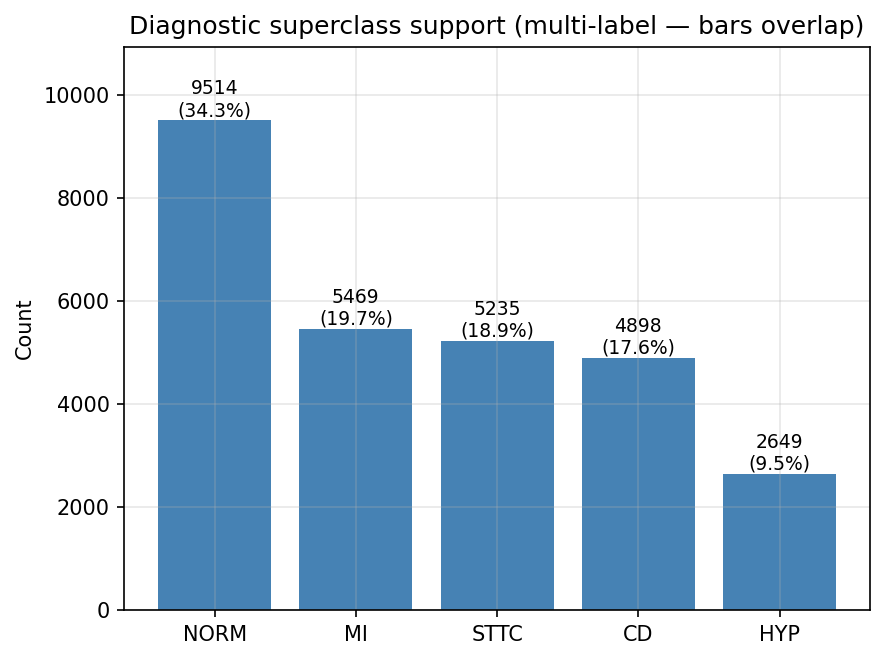

24.1% of records carry MORE THAN ONE superclass.
That is exactly why this is multi-label and why plain accuracy is not reported.



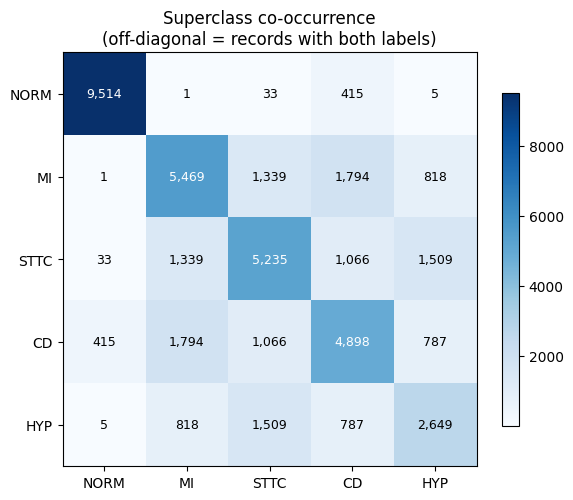

In [10]:
description = describe_dataset(database, labels, cfg)
save_json(description, RESULTS / "dataset_description.json")

plot_class_distribution(description["class_support"], RESULTS / "class_distribution.png",
                        title="Diagnostic superclass support (multi-label — bars overlap)")
display(Image(filename=str(RESULTS / "class_distribution.png")))

print(f"{100 * description['multi_label_fraction']:.1f}% of records carry MORE THAN ONE "
      "superclass.")
print("That is exactly why this is multi-label and why plain accuracy is not reported.\n")

# Co-occurrence: the diagonal is each class's support; off-diagonal entries are
# genuine simultaneous diagnoses.
co = pd.DataFrame(description["co_occurrence"])[CLASSES].loc[CLASSES]
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(co.to_numpy(), cmap="Blues")
ax.set_xticks(range(len(CLASSES)), CLASSES)
ax.set_yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        value = co.iloc[i, j]
        ax.text(j, i, f"{value:,}", ha="center", va="center", fontsize=9,
                color="white" if value > co.to_numpy().max() / 2 else "black")
ax.set_title("Superclass co-occurrence\n(off-diagonal = records with both labels)")
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.8)
plt.show()

## 6. Signal Preprocessing

Each step is justified, because "standard ECG preprocessing" is not a
justification and a filter applied for no reason destroys real morphology.

| Step | On? | Why |
|---|---|---|
| 0.5 Hz high-pass | **yes** | Removes respiration/electrode drift, which is not diagnostic and wrecks per-lead normalisation. Zero-phase (`filtfilt`) so the ST segment is not shifted in time |
| Low-pass | **no** | The 100 Hz files are already anti-alias filtered; another low-pass would blunt QRS upstrokes, which is what `CD` is about |
| 50 Hz notch | **no** | Handled upstream, and meaningless at/beyond Nyquist for a 100 Hz signal |
| Per-lead z-score | **yes** | Removes electrode/body-habitus amplitude variation. Computed **within each record**, so it is leakage-free by construction |
| Resampling | **no** | We read native 100 Hz files |
| 8σ clipping | **yes** | Caps electrode pops without touching real QRS peaks (~3–5σ) |

**Known cost:** per-lead z-scoring discards absolute voltage, which matters for
`HYP` (partly an amplitude criterion). Recorded as a limitation, not glossed over.

raw       : shape (1000, 12) (samples, leads), fs = 100 Hz
processed : shape (12, 1000) (leads, samples)
leads     : ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


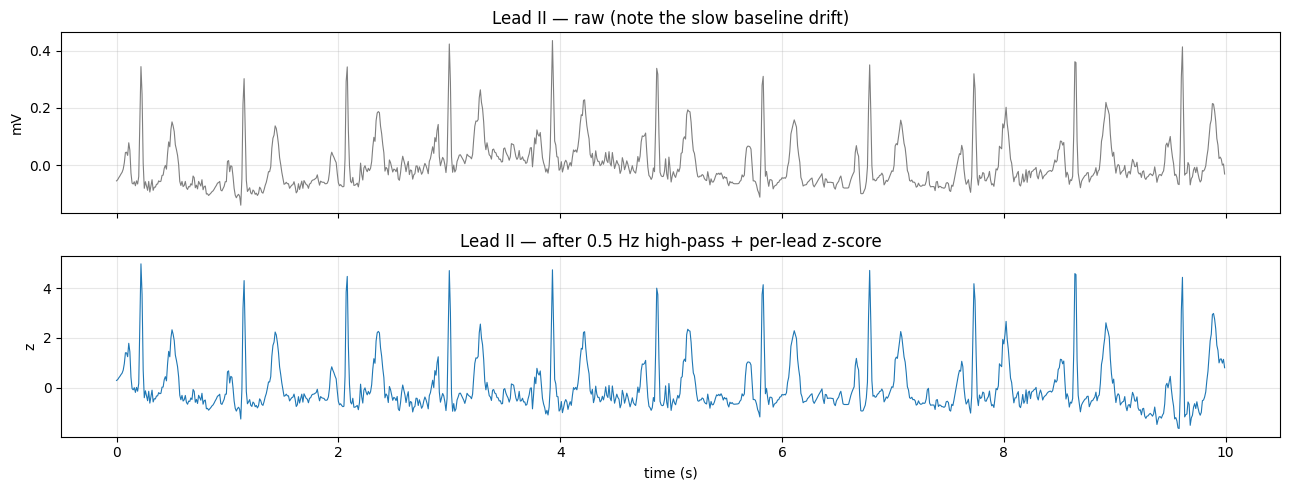

In [11]:
# Look at one record before and after preprocessing.
example_row = database.iloc[0]
raw_signal, header = load_raw_record(root / example_row.filename_lr)
processed = preprocess_signal(raw_signal, cfg)

print(f"raw       : shape {raw_signal.shape} (samples, leads), fs = {header['fs']} Hz")
print(f"processed : shape {processed.shape} (leads, samples)")
print(f"leads     : {header['sig_name']}")

fs = int(cfg.dataset.sampling_rate)
t = np.arange(processed.shape[-1]) / fs
lead = 1  # lead II

fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
axes[0].plot(t, raw_signal[:, lead], lw=0.8, color="tab:gray")
axes[0].set_title("Lead II — raw (note the slow baseline drift)")
axes[0].set_ylabel("mV")
axes[1].plot(t, processed[lead], lw=0.8, color="tab:blue")
axes[1].set_title("Lead II — after 0.5 Hz high-pass + per-lead z-score")
axes[1].set_ylabel("z")
axes[1].set_xlabel("time (s)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Build the waveform cache

Reading ~21,800 WFDB files is I/O-bound and slow, especially from Drive. We do it
once, preprocess, and save one contiguous `.npy` (~1.0 GB at 100 Hz) that is then
memory-mapped. Every later epoch reads from that instead of parsing files.

Baking preprocessing into the cache is safe **only** because every step is
per-record — no statistic is shared across records, so there is nothing to leak
between splits.

First run: several minutes. Later runs: instant.

In [12]:
# ============================================================
# RESTORE — SECTION 6
# ============================================================

root = resolve_ptbxl_root(cfg)

database, statements = load_metadata(cfg, root)

database, labels, label_report = build_superclass_labels(
    database,
    statements,
    cfg
)

# This should detect/use the existing cache
waveforms, cache_path = build_waveform_cache(
    database,
    cfg,
    root=root
)

print("Waveforms restored")
print("shape:", waveforms.shape)
print("dtype:", waveforms.dtype)
print("cache:", cache_path)

2026-09-29 09:28:47 | INFO     | cardiosense.ecg.data         | Loaded metadata: 21799 records, 18869 patients, 71 SCP statements
2026-09-29 09:28:47 | INFO     | cardiosense.ecg.data         | 44 diagnostic SCP codes map onto 5 superclasses
2026-09-29 09:28:47 | INFO     | cardiosense.ecg.data         | Dropped 411 records with no diagnostic superclass.
2026-09-29 09:28:47 | INFO     | cardiosense.ecg.data         | Labels built: 21388 records, prevalence {'NORM': 0.4448, 'MI': 0.2557, 'STTC': 0.2448, 'CD': 0.229, 'HYP': 0.1239}
2026-09-29 09:28:47 | INFO     | cardiosense.ecg.data         | 24.1% of records carry more than one superclass — this is why the task is multi-label and why plain accuracy is not reported.
2026-09-29 09:28:49 | INFO     | cardiosense.ecg.preprocessing | Using cached waveforms: waveforms_100hz_21388.npy (21388, 12, 1000)
Waveforms restored
shape: (21388, 12, 1000)
dtype: float32
cache: /content/drive/MyDrive/CardioSense/data/ecg/cache/waveforms_100hz_21388.npy

In [13]:
start = time.time()
waveforms, cache_path = build_waveform_cache(database, cfg, root=root)
print(f"waveforms: {waveforms.shape} ({waveforms.dtype}) in {time.time() - start:.1f}s")
print(f"cache    : {cache_path}")
print(f"size     : {cache_path.stat().st_size / 1024**3:.2f} GB")

2026-09-29 09:28:49 | INFO     | cardiosense.ecg.preprocessing | Using cached waveforms: waveforms_100hz_21388.npy (21388, 12, 1000)
waveforms: (21388, 12, 1000) (float32) in 0.0s
cache    : /content/drive/MyDrive/CardioSense/data/ecg/cache/waveforms_100hz_21388.npy
size     : 0.96 GB


## 7. Dataset Splitting — official `strat_fold`

PTB-XL ships a `strat_fold` column (1–10) assigned by the dataset authors:
stratified by diagnostic class **and patient-disjoint**.

Folds 1–8 train, 9 validation, 10 test. This is the published convention, so our
macro-AUC is comparable to the literature, and leakage is impossible by
construction.

**Never re-split PTB-XL randomly by record.** Patients contribute several ECGs; a
record-level shuffle puts the same patient on both sides of the split. The cell
below asserts patient disjointness rather than trusting it.

In [14]:
splits = split_by_fold(database, labels, cfg)

split_summary = {name: splits[name]["summary"] for name in ("train", "val", "test")}
split_summary["patient_overlap"] = splits["patient_overlap"]
save_json(split_summary, RESULTS / "split_summary.json")

print("patient overlap between splits (must be all zero):", splits["patient_overlap"])
pd.DataFrame({
    name: {
        "records": splits[name]["summary"]["n_records"],
        "patients": splits[name]["summary"]["n_patients"],
        **{f"prev_{c}": splits[name]["summary"]["prevalence"][c] for c in CLASSES},
    } for name in ("train", "val", "test")
})

2026-09-29 09:28:49 | INFO     | cardiosense.ecg.data         | train folds=[1, 2, 3, 4, 5, 6, 7, 8] records=17084 patients=14823
2026-09-29 09:28:49 | INFO     | cardiosense.ecg.data         | val   folds=[9] records= 2146 patients= 1917
2026-09-29 09:28:49 | INFO     | cardiosense.ecg.data         | test  folds=[10] records= 2158 patients= 1877
2026-09-29 09:28:49 | INFO     | cardiosense.ecg.data         | Patient overlap between splits: {'train_val': 0, 'train_test': 0, 'val_test': 0} (all zero = leakage-free)
patient overlap between splits (must be all zero): {'train_val': 0, 'train_test': 0, 'val_test': 0}


,train,val,test
records,17084.0000,2146.0000,2158.0000
patients,14823.0000,1917.0000,1877.0000
prev_NORM,0.4446,0.4450,0.4462
prev_MI,0.2563,0.2516,0.2549
prev_STTC,0.2450,0.2460,0.2414
prev_CD,0.2287,0.2307,0.2298
prev_HYP,0.1240,0.1249,0.1214


## 8. Baseline — Experiment E-A

11 statistics per lead (132 features), one-vs-rest Logistic Regression.

Its job is not to be good; it is to set the floor the CNN must clear. A network
that beats chance but not this has learned nothing a summary statistic could not.

**Structural prediction to check later:** these features are *global* over 10
seconds and discard temporal ordering entirely. ST elevation/depression is defined
by *where* a deflection sits relative to the QRS, so `STTC` and `MI` are where the
CNN should gain most. Worth verifying against the per-class numbers rather than
assuming.

In [15]:
from cardiosense.common.config import load_config
from cardiosense.common.paths import PATHS
from cardiosense.ecg.baseline import extract_feature_matrix, train_baseline
from cardiosense.ecg import evaluate as ev
from cardiosense.common.io_utils import save_pickle
import time
from pathlib import Path # Ensure Path is available

# Re-initialize cfg and related global variables if not already defined
# This makes the cell robust against kernel state loss for these variables.
cfg = load_config("ecg")
CLASSES = list(cfg.task.classes)
MODELS = PATHS.root / cfg.output.models_dir

features = list(cfg.baseline.features)
print(f"{len(features)} features x {cfg.dataset.n_leads} leads = "
      f"{len(features) * cfg.dataset.n_leads} total")
print(features)

start = time.time()
X_train = extract_feature_matrix(waveforms, splits["train"]["indices"], features)
X_val = extract_feature_matrix(waveforms, splits["val"]["indices"], features)
X_test = extract_feature_matrix(waveforms, splits["test"]["indices"], features)
print(f"\nfeature matrices: {X_train.shape} / {X_val.shape} / {X_test.shape} "
      f"in {time.time() - start:.1f}s")

y_train = splits["train"]["labels"]
y_val = splits["val"]["labels"]
y_test = splits["test"]["labels"]

baseline = train_baseline(X_train, y_train, X_val, cfg, X_test=X_test)
thr_baseline, _ = ev.tune_per_class_thresholds(y_val, baseline["val_prob"], cfg)
metrics_baseline = ev.evaluate_multilabel(
    y_test, baseline["test_prob"], thr_baseline, cfg, split_name="test/baseline"
)

experiments = {"statistical_baseline": {
    "metrics": metrics_baseline,
    "parameters": int(X_train.shape[1] * len(CLASSES)),
    "train_seconds": baseline["train_seconds"],
}}
save_pickle(baseline["model"], MODELS / "ecg_baseline.pkl")
ev.per_class_table(metrics_baseline, CLASSES)

11 features x 12 leads = 132 total
['mean', 'std', 'min', 'max', 'ptp', 'rms', 'skew', 'kurtosis', 'zero_crossing_rate', 'line_length', 'energy']


extracting features:   0%|          | 0/17084 [00:00<?, ?it/s]

extracting features:   0%|          | 0/2146 [00:00<?, ?it/s]

extracting features:   0%|          | 0/2158 [00:00<?, ?it/s]


feature matrices: (17084, 132) / (2146, 132) / (2158, 132) in 70.0s
2026-09-29 09:29:59 | INFO     | cardiosense.ecg.baseline     | Fitting one-vs-rest baseline: 132 features, 17084 records, 5 classes
2026-09-29 09:30:04 | INFO     | cardiosense.ecg.baseline     | Baseline fitted in 4.7s
2026-09-29 09:30:06 | INFO     | cardiosense.ecg.evaluate     | Per-class thresholds (f1, tuned on validation): {'NORM': 0.399, 'MI': 0.527, 'STTC': 0.591, 'CD': 0.591, 'HYP': 0.606}
2026-09-29 09:30:23 | INFO     | cardiosense.ecg.evaluate     | [test/baseline] macro ROC-AUC 0.8239 | macro PR-AUC 0.6029 | macro F1 0.6083 | exact-match 0.4124
2026-09-29 09:30:23 | INFO     | cardiosense.ecg.evaluate     |     NORM  AUC 0.878 | PR-AUC 0.827 | F1 0.789 | support 963
2026-09-29 09:30:23 | INFO     | cardiosense.ecg.evaluate     |     MI    AUC 0.777 | PR-AUC 0.521 | F1 0.557 | support 550
2026-09-29 09:30:23 | INFO     | cardiosense.ecg.evaluate     |     STTC  AUC 0.866 | PR-AUC 0.660 | F1 0.647 | suppo

,class,support,prevalence,threshold,roc_auc,pr_auc,precision,recall,f1,roc_auc_95ci
0,NORM,963,0.4462,0.399045,0.8782,0.8273,0.6963,0.9097,0.7888,"[0.864, 0.892]"
1,MI,550,0.2549,0.527085,0.7769,0.5213,0.4750,0.6727,0.5568,"[0.754, 0.799]"
2,STTC,521,0.2414,0.591106,0.8662,0.6601,0.5857,0.7217,0.6466,"[0.849, 0.881]"
3,CD,496,0.2298,0.591106,0.8394,0.6936,0.6512,0.6210,0.6357,"[0.820, 0.861]"
4,HYP,262,0.1214,0.605879,0.7591,0.3122,0.3341,0.5420,0.4134,"[0.729, 0.792]"


In [16]:
# ── Section 8 persistence ───────────────────────────────────────────────────
# Save everything needed to recover Section 8 after a Colab disconnect.

import json
import numpy as np
from pathlib import Path # Added import

# Re-initialize cfg and related global variables
from cardiosense.common.config import load_config
from cardiosense.common.paths import PATHS
from cardiosense.common.io_utils import save_pickle # Needed for save_pickle

cfg = load_config("ecg")
CLASSES = list(cfg.task.classes)
MODELS = PATHS.root / cfg.output.models_dir

ECG_RESULTS_DRIVE = Path("/content/drive/MyDrive/CardioSense/results/ecg")
ECG_MODELS_DRIVE = Path("/content/drive/MyDrive/CardioSense/models/ecg")

ECG_RESULTS_DRIVE.mkdir(parents=True, exist_ok=True)
ECG_MODELS_DRIVE.mkdir(parents=True, exist_ok=True)

# 1. Save feature matrices and labels
np.savez_compressed(
    ECG_RESULTS_DRIVE / "baseline_features.npz",
    X_train=X_train,
    X_val=X_val,
    X_test=X_test,
    y_train=y_train,
    y_val=y_val,
    y_test=y_test,
)

# 2. Save baseline validation/test probabilities
np.savez_compressed(
    ECG_RESULTS_DRIVE / "baseline_predictions.npz",
    val_prob=baseline["val_prob"],
    test_prob=baseline["test_prob"],
)

# 3. Save per-class baseline thresholds
with open(ECG_RESULTS_DRIVE / "baseline_thresholds.json", "w") as f:
    json.dump(
        {
            "classes": CLASSES,
            "thresholds": [float(x) for x in thr_baseline],
        },
        f,
        indent=2,
    )

# 4. Save baseline metrics
with open(ECG_RESULTS_DRIVE / "baseline_metrics.json", "w") as f:
    json.dump(
        metrics_baseline,
        f,
        indent=2,
        default=lambda x: float(x) if isinstance(x, np.generic) else x,
    )

# 5. Save experiment information
with open(ECG_RESULTS_DRIVE / "baseline_experiment.json", "w") as f:
    json.dump(
        experiments["statistical_baseline"],
        f,
        indent=2,
        default=lambda x: float(x) if isinstance(x, np.generic) else x,
    )

# 6. Save the sklearn baseline model
save_pickle(
    baseline["model"],
    ECG_MODELS_DRIVE / "ecg_baseline.pkl",
)

print("\nSection 8 artifacts saved to Drive:")
for p in [
    ECG_RESULTS_DRIVE / "baseline_features.npz",
    ECG_RESULTS_DRIVE / "baseline_predictions.npz",
    ECG_RESULTS_DRIVE / "baseline_thresholds.json",
    ECG_RESULTS_DRIVE / "baseline_metrics.json",
    ECG_RESULTS_DRIVE / "baseline_experiment.json",
    ECG_MODELS_DRIVE / "ecg_baseline.pkl",
]:
    print(" ", p)

print("\nSection 8 persistence complete.")


Section 8 artifacts saved to Drive:
  /content/drive/MyDrive/CardioSense/results/ecg/baseline_features.npz
  /content/drive/MyDrive/CardioSense/results/ecg/baseline_predictions.npz
  /content/drive/MyDrive/CardioSense/results/ecg/baseline_thresholds.json
  /content/drive/MyDrive/CardioSense/results/ecg/baseline_metrics.json
  /content/drive/MyDrive/CardioSense/results/ecg/baseline_experiment.json
  /content/drive/MyDrive/CardioSense/models/ecg/ecg_baseline.pkl

Section 8 persistence complete.


In [17]:
# ── Restore Section 8 ────────────────────────────────────────────────────────

import json
import numpy as np
from pathlib import Path # Added import

# Re-initialize cfg and related global variables
from cardiosense.common.config import load_config
from cardiosense.common.io_utils import load_pickle # Needed for load_pickle

cfg = load_config("ecg")
CLASSES = list(cfg.task.classes)

ECG_RESULTS_DRIVE = Path("/content/drive/MyDrive/CardioSense/results/ecg")
ECG_MODELS_DRIVE = Path("/content/drive/MyDrive/CardioSense/models/ecg")

# Restore feature matrices + labels
features_data = np.load(
    ECG_RESULTS_DRIVE / "baseline_features.npz",
    allow_pickle=False
)

X_train = features_data["X_train"]
X_val = features_data["X_val"]
X_test = features_data["X_test"]

y_train = features_data["y_train"]
y_val = features_data["y_val"]
y_test = features_data["y_test"]

# Restore probabilities
pred_data = np.load(
    ECG_RESULTS_DRIVE / "baseline_predictions.npz",
    allow_pickle=False
)

# Reconstruct baseline dictionary
baseline = {
    "val_prob": pred_data["val_prob"],
    "test_prob": pred_data["test_prob"],
}

# Restore sklearn model
baseline["model"] = load_pickle(
    ECG_MODELS_DRIVE / "ecg_baseline.pkl"
)

# Restore thresholds
with open(ECG_RESULTS_DRIVE / "baseline_thresholds.json") as f:
    threshold_data = json.load(f)

thr_baseline = np.array(
    threshold_data["thresholds"],
    dtype=np.float32
)

# Restore metrics
with open(ECG_RESULTS_DRIVE / "baseline_metrics.json") as f:
    metrics_baseline = json.load(f)

# Restore experiment information
with open(ECG_RESULTS_DRIVE / "baseline_experiment.json") as f:
    baseline_experiment = json.load(f)

experiments = {
    "statistical_baseline": baseline_experiment
}

features = list(cfg.baseline.features)

print("Section 8 restored.")
print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_val:  ", y_val.shape)
print("y_test: ", y_test.shape)
print("thresholds:", thr_baseline)
print("baseline model:", type(baseline["model"]).__name__)

Section 8 restored.
X_train: (17084, 132)
X_val:   (2146, 132)
X_test:  (2158, 132)
y_train: (17084, 5)
y_val:   (2146, 5)
y_test:  (2158, 5)
thresholds: [0.39904523 0.5270854  0.5911055  0.5911055  0.6058794 ]
baseline model: Pipeline


In [18]:
from cardiosense.common.config import load_config
from cardiosense.common.paths import PATHS
from cardiosense.ecg.baseline import extract_feature_matrix, train_baseline
from cardiosense.ecg import evaluate as ev
from cardiosense.common.io_utils import save_pickle
import time
from pathlib import Path # Ensure Path is available

# Re-initialize cfg and related global variables if not already defined
# This makes the cell robust against kernel state loss for these variables.
cfg = load_config("ecg")
CLASSES = list(cfg.task.classes)
MODELS = PATHS.root / cfg.output.models_dir

features = list(cfg.baseline.features)
print(f"{len(features)} features x {cfg.dataset.n_leads} leads = "
      f"{len(features) * cfg.dataset.n_leads} total")
print(features)

start = time.time()
X_train = extract_feature_matrix(waveforms, splits["train"]["indices"], features)
X_val = extract_feature_matrix(waveforms, splits["val"]["indices"], features)
X_test = extract_feature_matrix(waveforms, splits["test"]["indices"], features)
print(f"\nfeature matrices: {X_train.shape} / {X_val.shape} / {X_test.shape} "
      f"in {time.time() - start:.1f}s")

y_train = splits["train"]["labels"]
y_val = splits["val"]["labels"]
y_test = splits["test"]["labels"]

baseline = train_baseline(X_train, y_train, X_val, cfg, X_test=X_test)
thr_baseline, _ = ev.tune_per_class_thresholds(y_val, baseline["val_prob"], cfg)
metrics_baseline = ev.evaluate_multilabel(
    y_test, baseline["test_prob"], thr_baseline, cfg, split_name="test/baseline"
)

experiments = {"statistical_baseline": {
    "metrics": metrics_baseline,
    "parameters": int(X_train.shape[1] * len(CLASSES)),
    "train_seconds": baseline["train_seconds"],
}}
save_pickle(baseline["model"], MODELS / "ecg_baseline.pkl")
ev.per_class_table(metrics_baseline, CLASSES)

11 features x 12 leads = 132 total
['mean', 'std', 'min', 'max', 'ptp', 'rms', 'skew', 'kurtosis', 'zero_crossing_rate', 'line_length', 'energy']


extracting features:   0%|          | 0/17084 [00:00<?, ?it/s]

extracting features:   0%|          | 0/2146 [00:00<?, ?it/s]

extracting features:   0%|          | 0/2158 [00:00<?, ?it/s]


feature matrices: (17084, 132) / (2146, 132) / (2158, 132) in 59.8s
2026-09-29 09:31:27 | INFO     | cardiosense.ecg.baseline     | Fitting one-vs-rest baseline: 132 features, 17084 records, 5 classes
2026-09-29 09:31:30 | INFO     | cardiosense.ecg.baseline     | Baseline fitted in 2.4s
2026-09-29 09:31:32 | INFO     | cardiosense.ecg.evaluate     | Per-class thresholds (f1, tuned on validation): {'NORM': 0.399, 'MI': 0.527, 'STTC': 0.591, 'CD': 0.591, 'HYP': 0.606}
2026-09-29 09:31:48 | INFO     | cardiosense.ecg.evaluate     | [test/baseline] macro ROC-AUC 0.8239 | macro PR-AUC 0.6029 | macro F1 0.6083 | exact-match 0.4124
2026-09-29 09:31:48 | INFO     | cardiosense.ecg.evaluate     |     NORM  AUC 0.878 | PR-AUC 0.827 | F1 0.789 | support 963
2026-09-29 09:31:48 | INFO     | cardiosense.ecg.evaluate     |     MI    AUC 0.777 | PR-AUC 0.521 | F1 0.557 | support 550
2026-09-29 09:31:48 | INFO     | cardiosense.ecg.evaluate     |     STTC  AUC 0.866 | PR-AUC 0.660 | F1 0.647 | suppo

,class,support,prevalence,threshold,roc_auc,pr_auc,precision,recall,f1,roc_auc_95ci
0,NORM,963,0.4462,0.399045,0.8782,0.8273,0.6963,0.9097,0.7888,"[0.864, 0.892]"
1,MI,550,0.2549,0.527085,0.7769,0.5213,0.4750,0.6727,0.5568,"[0.754, 0.799]"
2,STTC,521,0.2414,0.591106,0.8662,0.6601,0.5857,0.7217,0.6466,"[0.849, 0.881]"
3,CD,496,0.2298,0.591106,0.8394,0.6936,0.6512,0.6210,0.6357,"[0.820, 0.861]"
4,HYP,262,0.1214,0.605879,0.7591,0.3122,0.3341,0.5420,0.4134,"[0.729, 0.792]"


In [19]:
# ── Section 8 persistence ───────────────────────────────────────────────────
# Save everything needed to recover Section 8 after a Colab disconnect.

import json
import numpy as np
from pathlib import Path # Added import

# Re-initialize cfg and related global variables
from cardiosense.common.config import load_config
from cardiosense.common.paths import PATHS
from cardiosense.common.io_utils import save_pickle # Needed for save_pickle

cfg = load_config("ecg")
CLASSES = list(cfg.task.classes)
MODELS = PATHS.root / cfg.output.models_dir

ECG_RESULTS_DRIVE = Path("/content/drive/MyDrive/CardioSense/results/ecg")
ECG_MODELS_DRIVE = Path("/content/drive/MyDrive/CardioSense/models/ecg")

ECG_RESULTS_DRIVE.mkdir(parents=True, exist_ok=True)
ECG_MODELS_DRIVE.mkdir(parents=True, exist_ok=True)

# 1. Save feature matrices and labels
np.savez_compressed(
    ECG_RESULTS_DRIVE / "baseline_features.npz",
    X_train=X_train,
    X_val=X_val,
    X_test=X_test,
    y_train=y_train,
    y_val=y_val,
    y_test=y_test,
)

# 2. Save baseline validation/test probabilities
np.savez_compressed(
    ECG_RESULTS_DRIVE / "baseline_predictions.npz",
    val_prob=baseline["val_prob"],
    test_prob=baseline["test_prob"],
)

# 3. Save per-class baseline thresholds
with open(ECG_RESULTS_DRIVE / "baseline_thresholds.json", "w") as f:
    json.dump(
        {
            "classes": CLASSES,
            "thresholds": [float(x) for x in thr_baseline],
        },
        f,
        indent=2,
    )

# 4. Save baseline metrics
with open(ECG_RESULTS_DRIVE / "baseline_metrics.json", "w") as f:
    json.dump(
        metrics_baseline,
        f,
        indent=2,
        default=lambda x: float(x) if isinstance(x, np.generic) else x,
    )

# 5. Save experiment information
with open(ECG_RESULTS_DRIVE / "baseline_experiment.json", "w") as f:
    json.dump(
        experiments["statistical_baseline"],
        f,
        indent=2,
        default=lambda x: float(x) if isinstance(x, np.generic) else x,
    )

# 6. Save the sklearn baseline model
save_pickle(
    baseline["model"],
    ECG_MODELS_DRIVE / "ecg_baseline.pkl",
)

print("\nSection 8 artifacts saved to Drive:")
for p in [
    ECG_RESULTS_DRIVE / "baseline_features.npz",
    ECG_RESULTS_DRIVE / "baseline_predictions.npz",
    ECG_RESULTS_DRIVE / "baseline_thresholds.json",
    ECG_RESULTS_DRIVE / "baseline_metrics.json",
    ECG_RESULTS_DRIVE / "baseline_experiment.json",
    ECG_MODELS_DRIVE / "ecg_baseline.pkl",
]:
    print(" ", p)

print("\nSection 8 persistence complete.")


Section 8 artifacts saved to Drive:
  /content/drive/MyDrive/CardioSense/results/ecg/baseline_features.npz
  /content/drive/MyDrive/CardioSense/results/ecg/baseline_predictions.npz
  /content/drive/MyDrive/CardioSense/results/ecg/baseline_thresholds.json
  /content/drive/MyDrive/CardioSense/results/ecg/baseline_metrics.json
  /content/drive/MyDrive/CardioSense/results/ecg/baseline_experiment.json
  /content/drive/MyDrive/CardioSense/models/ecg/ecg_baseline.pkl

Section 8 persistence complete.


In [20]:
# ── Restore Section 8 ────────────────────────────────────────────────────────

import json
import numpy as np
from pathlib import Path # Added import

# Re-initialize cfg and related global variables
from cardiosense.common.config import load_config
from cardiosense.common.io_utils import load_pickle # Needed for load_pickle

cfg = load_config("ecg")
CLASSES = list(cfg.task.classes)

ECG_RESULTS_DRIVE = Path("/content/drive/MyDrive/CardioSense/results/ecg")
ECG_MODELS_DRIVE = Path("/content/drive/MyDrive/CardioSense/models/ecg")

# Restore feature matrices + labels
features_data = np.load(
    ECG_RESULTS_DRIVE / "baseline_features.npz",
    allow_pickle=False
)

X_train = features_data["X_train"]
X_val = features_data["X_val"]
X_test = features_data["X_test"]

y_train = features_data["y_train"]
y_val = features_data["y_val"]
y_test = features_data["y_test"]

# Restore probabilities
pred_data = np.load(
    ECG_RESULTS_DRIVE / "baseline_predictions.npz",
    allow_pickle=False
)

# Reconstruct baseline dictionary
baseline = {
    "val_prob": pred_data["val_prob"],
    "test_prob": pred_data["test_prob"],
}

# Restore sklearn model
baseline["model"] = load_pickle(
    ECG_MODELS_DRIVE / "ecg_baseline.pkl"
)

# Restore thresholds
with open(ECG_RESULTS_DRIVE / "baseline_thresholds.json") as f:
    threshold_data = json.load(f)

thr_baseline = np.array(
    threshold_data["thresholds"],
    dtype=np.float32
)

# Restore metrics
with open(ECG_RESULTS_DRIVE / "baseline_metrics.json") as f:
    metrics_baseline = json.load(f)

# Restore experiment information
with open(ECG_RESULTS_DRIVE / "baseline_experiment.json") as f:
    baseline_experiment = json.load(f)

experiments = {
    "statistical_baseline": baseline_experiment
}

features = list(cfg.baseline.features)

print("Section 8 restored.")
print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_val:  ", y_val.shape)
print("y_test: ", y_test.shape)
print("thresholds:", thr_baseline)
print("baseline model:", type(baseline["model"]).__name__)

Section 8 restored.
X_train: (17084, 132)
X_val:   (2146, 132)
X_test:  (2158, 132)
y_train: (17084, 5)
y_val:   (2146, 5)
y_test:  (2158, 5)
thresholds: [0.39904523 0.5270854  0.5911055  0.5911055  0.6058794 ]
baseline model: Pipeline


In [21]:
from cardiosense.common.config import load_config
from cardiosense.common.paths import PATHS
from cardiosense.ecg.baseline import extract_feature_matrix, train_baseline
from cardiosense.ecg import evaluate as ev
from cardiosense.common.io_utils import save_pickle
import time
from pathlib import Path

# Re-initialize cfg and related global variables for robustness
cfg = load_config("ecg")
CLASSES = list(cfg.task.classes)
MODELS = PATHS.root / cfg.output.models_dir

features = list(cfg.baseline.features)
print(f"{len(features)} features x {cfg.dataset.n_leads} leads = "
      f"{len(features) * cfg.dataset.n_leads} total")
print(features)

start = time.time()
X_train = extract_feature_matrix(waveforms, splits["train"]["indices"], features)
X_val = extract_feature_matrix(waveforms, splits["val"]["indices"], features)
X_test = extract_feature_matrix(waveforms, splits["test"]["indices"], features)
print(f"\nfeature matrices: {X_train.shape} / {X_val.shape} / {X_test.shape} "
      f"in {time.time() - start:.1f}s")

y_train = splits["train"]["labels"]
y_val = splits["val"]["labels"]
y_test = splits["test"]["labels"]

baseline = train_baseline(X_train, y_train, X_val, cfg, X_test=X_test)
thr_baseline, _ = ev.tune_per_class_thresholds(y_val, baseline["val_prob"], cfg)
metrics_baseline = ev.evaluate_multilabel(
    y_test, baseline["test_prob"], thr_baseline, cfg, split_name="test/baseline"
)

experiments = {"statistical_baseline": {
    "metrics": metrics_baseline,
    "parameters": int(X_train.shape[1] * len(CLASSES)),
    "train_seconds": baseline["train_seconds"],
}}
save_pickle(baseline["model"], MODELS / "ecg_baseline.pkl")
ev.per_class_table(metrics_baseline, CLASSES)

11 features x 12 leads = 132 total
['mean', 'std', 'min', 'max', 'ptp', 'rms', 'skew', 'kurtosis', 'zero_crossing_rate', 'line_length', 'energy']


extracting features:   0%|          | 0/17084 [00:00<?, ?it/s]

extracting features:   0%|          | 0/2146 [00:00<?, ?it/s]

extracting features:   0%|          | 0/2158 [00:00<?, ?it/s]


feature matrices: (17084, 132) / (2146, 132) / (2158, 132) in 59.6s
2026-09-29 09:32:49 | INFO     | cardiosense.ecg.baseline     | Fitting one-vs-rest baseline: 132 features, 17084 records, 5 classes
2026-09-29 09:32:52 | INFO     | cardiosense.ecg.baseline     | Baseline fitted in 3.1s
2026-09-29 09:32:55 | INFO     | cardiosense.ecg.evaluate     | Per-class thresholds (f1, tuned on validation): {'NORM': 0.399, 'MI': 0.527, 'STTC': 0.591, 'CD': 0.591, 'HYP': 0.606}
2026-09-29 09:33:12 | INFO     | cardiosense.ecg.evaluate     | [test/baseline] macro ROC-AUC 0.8239 | macro PR-AUC 0.6029 | macro F1 0.6083 | exact-match 0.4124
2026-09-29 09:33:12 | INFO     | cardiosense.ecg.evaluate     |     NORM  AUC 0.878 | PR-AUC 0.827 | F1 0.789 | support 963
2026-09-29 09:33:12 | INFO     | cardiosense.ecg.evaluate     |     MI    AUC 0.777 | PR-AUC 0.521 | F1 0.557 | support 550
2026-09-29 09:33:12 | INFO     | cardiosense.ecg.evaluate     |     STTC  AUC 0.866 | PR-AUC 0.660 | F1 0.647 | suppo

,class,support,prevalence,threshold,roc_auc,pr_auc,precision,recall,f1,roc_auc_95ci
0,NORM,963,0.4462,0.399045,0.8782,0.8273,0.6963,0.9097,0.7888,"[0.864, 0.892]"
1,MI,550,0.2549,0.527085,0.7769,0.5213,0.4750,0.6727,0.5568,"[0.754, 0.799]"
2,STTC,521,0.2414,0.591106,0.8662,0.6601,0.5857,0.7217,0.6466,"[0.849, 0.881]"
3,CD,496,0.2298,0.591106,0.8394,0.6936,0.6512,0.6210,0.6357,"[0.820, 0.861]"
4,HYP,262,0.1214,0.605879,0.7591,0.3122,0.3341,0.5420,0.4134,"[0.729, 0.792]"


In [22]:
# ── Section 8 persistence ───────────────────────────────────────────────────
# Save everything needed to recover Section 8 after a Colab disconnect.

import json
import numpy as np

ECG_RESULTS_DRIVE = Path("/content/drive/MyDrive/CardioSense/results/ecg")
ECG_MODELS_DRIVE = Path("/content/drive/MyDrive/CardioSense/models/ecg")

ECG_RESULTS_DRIVE.mkdir(parents=True, exist_ok=True)
ECG_MODELS_DRIVE.mkdir(parents=True, exist_ok=True)

# 1. Save feature matrices and labels
np.savez_compressed(
    ECG_RESULTS_DRIVE / "baseline_features.npz",
    X_train=X_train,
    X_val=X_val,
    X_test=X_test,
    y_train=y_train,
    y_val=y_val,
    y_test=y_test,
)

# 2. Save baseline validation/test probabilities
np.savez_compressed(
    ECG_RESULTS_DRIVE / "baseline_predictions.npz",
    val_prob=baseline["val_prob"],
    test_prob=baseline["test_prob"],
)

# 3. Save per-class baseline thresholds
with open(ECG_RESULTS_DRIVE / "baseline_thresholds.json", "w") as f:
    json.dump(
        {
            "classes": CLASSES,
            "thresholds": [float(x) for x in thr_baseline],
        },
        f,
        indent=2,
    )

# 4. Save baseline metrics
with open(ECG_RESULTS_DRIVE / "baseline_metrics.json", "w") as f:
    json.dump(
        metrics_baseline,
        f,
        indent=2,
        default=lambda x: float(x) if isinstance(x, np.generic) else x,
    )

# 5. Save experiment information
with open(ECG_RESULTS_DRIVE / "baseline_experiment.json", "w") as f:
    json.dump(
        experiments["statistical_baseline"],
        f,
        indent=2,
        default=lambda x: float(x) if isinstance(x, np.generic) else x,
    )

# 6. Save the sklearn baseline model
save_pickle(
    baseline["model"],
    ECG_MODELS_DRIVE / "ecg_baseline.pkl",
)

print("\nSection 8 artifacts saved to Drive:")
for p in [
    ECG_RESULTS_DRIVE / "baseline_features.npz",
    ECG_RESULTS_DRIVE / "baseline_predictions.npz",
    ECG_RESULTS_DRIVE / "baseline_thresholds.json",
    ECG_RESULTS_DRIVE / "baseline_metrics.json",
    ECG_RESULTS_DRIVE / "baseline_experiment.json",
    ECG_MODELS_DRIVE / "ecg_baseline.pkl",
]:
    print(" ", p)

print("\nSection 8 persistence complete.")


Section 8 artifacts saved to Drive:
  /content/drive/MyDrive/CardioSense/results/ecg/baseline_features.npz
  /content/drive/MyDrive/CardioSense/results/ecg/baseline_predictions.npz
  /content/drive/MyDrive/CardioSense/results/ecg/baseline_thresholds.json
  /content/drive/MyDrive/CardioSense/results/ecg/baseline_metrics.json
  /content/drive/MyDrive/CardioSense/results/ecg/baseline_experiment.json
  /content/drive/MyDrive/CardioSense/models/ecg/ecg_baseline.pkl

Section 8 persistence complete.


In [23]:
# ── Restore Section 8 ────────────────────────────────────────────────────────

import json
import numpy as np

ECG_RESULTS_DRIVE = Path("/content/drive/MyDrive/CardioSense/results/ecg")
ECG_MODELS_DRIVE = Path("/content/drive/MyDrive/CardioSense/models/ecg")

# Restore feature matrices + labels
features_data = np.load(
    ECG_RESULTS_DRIVE / "baseline_features.npz",
    allow_pickle=False
)

X_train = features_data["X_train"]
X_val = features_data["X_val"]
X_test = features_data["X_test"]

y_train = features_data["y_train"]
y_val = features_data["y_val"]
y_test = features_data["y_test"]

# Restore probabilities
pred_data = np.load(
    ECG_RESULTS_DRIVE / "baseline_predictions.npz",
    allow_pickle=False
)

# Reconstruct baseline dictionary
baseline = {
    "val_prob": pred_data["val_prob"],
    "test_prob": pred_data["test_prob"],
}

# Restore sklearn model
baseline["model"] = load_pickle(
    ECG_MODELS_DRIVE / "ecg_baseline.pkl"
)

# Restore thresholds
with open(ECG_RESULTS_DRIVE / "baseline_thresholds.json") as f:
    threshold_data = json.load(f)

thr_baseline = np.array(
    threshold_data["thresholds"],
    dtype=np.float32
)

# Restore metrics
with open(ECG_RESULTS_DRIVE / "baseline_metrics.json") as f:
    metrics_baseline = json.load(f)

# Restore experiment information
with open(ECG_RESULTS_DRIVE / "baseline_experiment.json") as f:
    baseline_experiment = json.load(f)

experiments = {
    "statistical_baseline": baseline_experiment
}

features = list(cfg.baseline.features)

print("Section 8 restored.")
print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_val:  ", y_val.shape)
print("y_test: ", y_test.shape)
print("thresholds:", thr_baseline)
print("baseline model:", type(baseline["model"]).__name__)

Section 8 restored.
X_train: (17084, 132)
X_val:   (2146, 132)
X_test:  (2158, 132)
y_train: (17084, 5)
y_val:   (2146, 5)
y_test:  (2158, 5)
thresholds: [0.39904523 0.5270854  0.5911055  0.5911055  0.6058794 ]
baseline model: Pipeline


## 9. Model Definition — 1D CNN (Experiment E-B)

Four convolutional stages. Kernel size 7 at 100 Hz spans 70 ms — about the width
of a QRS complex, so a first-layer filter can respond to a whole complex rather
than a fragment. Each stage halves the time axis, so by the last stage the
receptive field covers several beats.

A 1D convolution slides along time across **all 12 leads at once**, which matches
the physiology: the leads are simultaneous views of the same electrical event, not
independent channels to be merged at the end.

Not deeper, because ~17k records with no pretraining will overfit a large network
before it generalises. The head emits **raw logits** — `BCEWithLogitsLoss` fuses
the sigmoid into the loss for numerical stability.

In [24]:
# Build model on GPU
model = build_model(cfg).to(device)

# model_summary() creates its dummy input on CPU,
# so temporarily move the model to CPU for the summary.
model_cpu = model.cpu()

architecture = model_summary(
    model_cpu,
    input_shape=(2, cfg.dataset.n_leads, cfg.dataset.signal_length)
)

# Put the actual training model back on GPU
model = model_cpu.to(device)

print(json.dumps(architecture, indent=2))
print(model)
print("Training device:", next(model.parameters()).device)

2026-09-29 09:33:13 | INFO     | cardiosense.ecg.models       | Built cnn1d: 371,013 parameters
{
  "class": "ECGCNN1D",
  "total": 371013,
  "trainable": 371013,
  "size_mb": 1.42,
  "output_shape": [
    2,
    5
  ]
}
ECGCNN1D(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv1d(12, 32, kernel_size=(7,), stride=(1,), padding=(3,), bias=False)
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (4): Dropout(p=0.3, inplace=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv1d(32, 64, kernel_size=(7,), stride=(1,), padding=(3,), bias=False)
        (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=Fal

## 10. Training

Monitored metric is **`val_macro_auc`**, not validation loss. Loss is dominated by
the common classes, so it can improve while `HYP` — the rare and clinically
interesting one — degrades. Macro AUC weights all five classes equally and is
threshold-free.

**If Colab disconnects, just re-run this cell.** Every epoch writes `last.pt` with
model, optimiser, scheduler, AMP scaler and RNG state; training resumes at the
next epoch.

In [25]:
# ============================================================
# RESTORE — SECTION 10
# ============================================================

for checkpoint in DRIVE_ECG_CHECKPOINTS.glob("*.pt"):
    shutil.copy2(
        checkpoint,
        CHECKPOINTS / checkpoint.name
    )

print("Checkpoints restored:")
for p in sorted(CHECKPOINTS.glob("*")):
    print(" ", p.name)

Checkpoints restored:


In [26]:
# ── Fix ECG DataLoader worker crashes ────────────────────────────────────────

cfg.training["num_workers"] = 0

loaders = build_dataloaders(
    waveforms,
    labels,
    splits,
    cfg
)

print("\nDataLoader workers fixed:")
for name, loader in loaders.items():
    print(
        f"{name}: "
        f"{len(loader.dataset)} records, "
        f"{len(loader)} batches, "
        f"workers={loader.num_workers}"
    )

2026-09-29 09:33:13 | INFO     | cardiosense.ecg.dataset      | train loader: 17084 records, 134 batches, augment=True
2026-09-29 09:33:13 | INFO     | cardiosense.ecg.dataset      | val   loader: 2146 records, 17 batches, augment=False
2026-09-29 09:33:13 | INFO     | cardiosense.ecg.dataset      | test  loader: 2158 records, 17 batches, augment=False

DataLoader workers fixed:
train: 17084 records, 134 batches, workers=0
val: 2146 records, 17 batches, workers=0
test: 2158 records, 17 batches, workers=0


### Fix — `pos_weight` was never computed

`compute_pos_weight` is imported in §2 but was never called, so the training
cell below referenced an undefined `pos_weight`. Practically, this means
`BCEWithLogitsLoss` was running **unweighted**: every class's errors counted
equally in the loss even though prevalence runs from ~12% (`HYP`) to ~44%
(`NORM`). An unweighted loss lets the optimiser ignore the rare classes almost
entirely, which is the opposite of what per-class thresholds and macro-AUC
monitoring are trying to correct for downstream.

The cell below computes a per-class `pos_weight = n_negative / n_positive` on
**train labels only** (no leakage) and passes it into training. Weights are
clamped to a max of 10x so the rarest class doesn't destabilise the loss early
in training — that cap is a judgment call, not a fixed literature value, so
treat it as a first setting to revisit if `HYP` still lags after this change.

In [27]:
# ── Compute class-balanced pos_weight for BCEWithLogitsLoss ─────────────────
# neg/pos ratio per class, from TRAIN labels only. Capped to avoid a rare
# class blowing up the loss scale early in training.
train_labels = splits["train"]["labels"]

try:
    pos_weight = compute_pos_weight(train_labels)
except TypeError:
    # some implementations take the config too
    pos_weight = compute_pos_weight(train_labels, cfg)

if not torch.is_tensor(pos_weight):
    pos_weight = torch.as_tensor(pos_weight, dtype=torch.float32)

POS_WEIGHT_CAP = 10.0
pos_weight = pos_weight.clamp(max=POS_WEIGHT_CAP).to(device)

print("Per-class pos_weight (neg/pos on train, capped at "
      f"{POS_WEIGHT_CAP:.0f}x):")
for name, w in zip(CLASSES, pos_weight.tolist()):
    n_pos = int(train_labels[:, CLASSES.index(name)].sum())
    n_neg = train_labels.shape[0] - n_pos
    print(f"  {name:6s}: weight={w:5.2f}  (pos={n_pos}, neg={n_neg})")

2026-09-29 09:33:13 | INFO     | cardiosense.ecg.dataset      | pos_weight per class: [1.2489999532699585, 2.9010000228881836, 3.0810000896453857, 3.372999906539917, 7.061999797821045]
Per-class pos_weight (neg/pos on train, capped at 10x):
  NORM  : weight= 1.25  (pos=7596, neg=9488)
  MI    : weight= 2.90  (pos=4379, neg=12705)
  STTC  : weight= 3.08  (pos=4186, neg=12898)
  CD    : weight= 3.37  (pos=3907, neg=13177)
  HYP   : weight= 7.06  (pos=2119, neg=14965)


In [28]:
training_result = train_model(
    model, loaders, cfg, device, CHECKPOINTS,
    pos_weight=pos_weight, experiment_name=str(cfg.model.name),
)

print(f"\nbest {training_result['monitor']} = {training_result['best_value']:.4f} "
      f"at epoch {training_result['best_epoch']}")
print(f"epochs run: {training_result['epochs_run']} "
      f"(resumed from epoch {training_result['resumed_from']})")
print(f"time      : {training_result['total_seconds']:.0f}s "
      f"({training_result['seconds_per_epoch']:.1f}s/epoch)")

2026-09-29 09:33:13 | INFO     | cardiosense.ecg.trainer      | Training cnn1d: epochs 1-40, device=cuda, AMP=True, monitor=val_macro_auc (max)


epoch 1/40 [train]:   0%|          | 0/134 [00:00<?, ?it/s]

2026-09-29 09:33:19 | INFO     | cardiosense.common.training  | New best val_macro_auc = 0.85868 at epoch 0 -> best.pt
2026-09-29 09:33:19 | INFO     | cardiosense.ecg.trainer      | epoch  1/40 | train loss 0.8813 | val loss 0.7426 | macro AUC 0.8587 | macro F1 0.6041 | lr 1.00e-03  <- best


epoch 2/40 [train]:   0%|          | 0/134 [00:00<?, ?it/s]

2026-09-29 09:33:22 | INFO     | cardiosense.common.training  | New best val_macro_auc = 0.87671 at epoch 1 -> best.pt
2026-09-29 09:33:22 | INFO     | cardiosense.ecg.trainer      | epoch  2/40 | train loss 0.6981 | val loss 0.7643 | macro AUC 0.8767 | macro F1 0.5859 | lr 1.00e-03  <- best


...

2026-09-29 09:34:44 | INFO     | cardiosense.ecg.trainer      | epoch 28/40 | train loss 0.5153 | val loss 0.5888 | macro AUC 0.9107 | macro F1 0.7097 | lr 2.50e-04


epoch 29/40 [train]:   0%|          | 0/134 [00:00<?, ?it/s]

2026-09-29 09:34:48 | INFO     | cardiosense.ecg.trainer      | epoch 29/40 | train loss 0.5171 | val loss 0.5866 | macro AUC 0.9110 | macro F1 0.7128 | lr 2.50e-04


epoch 30/40 [train]:   0%|          | 0/134 [00:00<?, ?it/s]

2026-09-29 09:34:51 | INFO     | cardiosense.common.training  | Early stopping: no improvement in 8 epochs (best=0.91107 at epoch 22)
2026-09-29 09:34:51 | INFO     | cardiosense.ecg.trainer      | epoch 30/40 | train loss 0.5117 | val loss 0.5984 | macro AUC 0.9103 | macro F1 0.7100 | lr 2.50e-04
2026-09-29 09:34:51 | INFO     | cardiosense.ecg.trainer      | Early stopping at epoch 30 (best val_macro_auc = 0.9111 at epoch 22).
2026-09-29 09:34:51 | INFO     | cardiosense.common.training  | Loaded weights from best.pt (epoch 21)
2026-09-29 09:34:51 | INFO     | cardiosense.ecg.trainer      | Training complete in 97.9s. Best val_macro_auc = 0.9111 at epoch 22.

best val_macro_auc = 0.9111 at epoch 22
epochs run: 30 (resumed from epoch 0)
time      : 98s (3.3s/epoch)


### Additional lever — moderate oversampling of rare-class training samples

`pos_weight` alone (previous run) barely moved macro F1/AUC — the class-imbalance
correction it applies is at the loss-gradient level only; the model still only
*sees* HYP 262 times per epoch out of ~17k train records. This adds a
`WeightedRandomSampler` on the **train loader only** (val/test distributions are
left untouched, so evaluation stays honest) that oversamples records containing
a rare class more often per epoch.

Weights use **sqrt(inverse frequency)**, not raw inverse frequency, deliberately
— raw inverse frequency for HYP (~12% prevalence) would mean each HYP record
gets shown ~8x as often, which risks overfitting to those specific 262 waveforms
given how few there are. sqrt damps that to ~2.9x, a more moderate correction
that's less likely to just memorize the minority set.

This is a real, uncertain intervention, not a guaranteed fix — the honest
expectation is that this plus `pos_weight` narrows the gap for `HYP`/`MI` some,
but probably doesn't get a 4-layer CNN all the way to beating the paper's
0.75 macro F1 by itself. The optional ResNet-1D cell later in the notebook is
the higher-capacity lever if this isn't enough.

In [29]:
# ── Oversample rare-class training records (train loader only) ─────────────
from torch.utils.data import DataLoader, WeightedRandomSampler

class_freq = train_labels.mean(axis=0)  # prevalence per class, train only
inv_sqrt_freq = 1.0 / np.sqrt(np.clip(class_freq, 1e-6, None))

# each sample's weight = strongest (rarest) positive class it carries;
# samples with no positive label (if any) fall back to weight 1.0
per_sample_class_w = train_labels * inv_sqrt_freq[None, :]
sample_weights = per_sample_class_w.max(axis=1)
sample_weights = np.where(sample_weights > 0, sample_weights, 1.0)
sample_weights = torch.as_tensor(sample_weights, dtype=torch.double)

train_sampler = WeightedRandomSampler(
    sample_weights, num_samples=len(sample_weights), replacement=True
)

_train_loader_old = loaders["train"]
loaders["train"] = DataLoader(
    _train_loader_old.dataset,
    batch_size=_train_loader_old.batch_size,
    sampler=train_sampler,
    num_workers=getattr(_train_loader_old, "num_workers", 0),
    pin_memory=getattr(_train_loader_old, "pin_memory", False),
    collate_fn=getattr(_train_loader_old, "collate_fn", None),
)

print("Per-class train prevalence and sampling weight:")
for name, freq, w in zip(CLASSES, class_freq, inv_sqrt_freq):
    print(f"  {name:6s}: prevalence={freq:.3f}  sample_weight={w:.2f}")

Per-class train prevalence and sampling weight:
  NORM  : prevalence=0.445  sample_weight=1.50
  MI    : prevalence=0.256  sample_weight=1.98
  STTC  : prevalence=0.245  sample_weight=2.02
  CD    : prevalence=0.229  sample_weight=2.09
  HYP   : prevalence=0.124  sample_weight=2.84


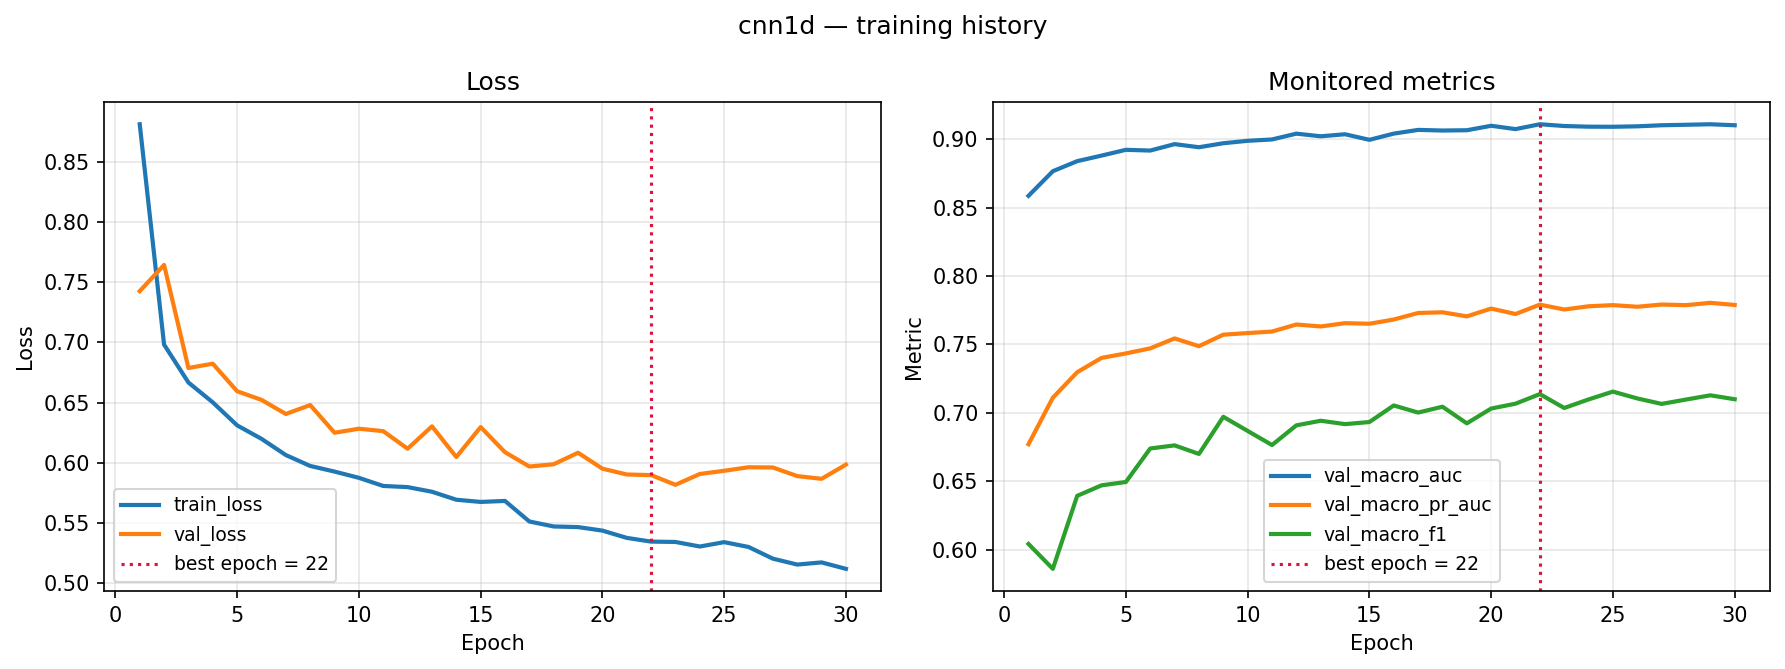

,train_loss,val_loss,val_macro_auc,val_macro_pr_auc,val_macro_f1,learning_rate
20,0.5375,0.5902,0.9075,0.7723,0.7067,0.0005
21,0.5344,0.5897,0.9111,0.7792,0.7137,0.0005
22,0.5341,0.5816,0.9098,0.7756,0.7036,0.0005
23,0.5303,0.5906,0.9093,0.7779,0.7098,0.0005
24,0.5339,0.5932,0.9092,0.7788,0.7156,0.0005
25,0.5299,0.5962,0.9095,0.7776,0.7106,0.0005
26,0.5202,0.5960,0.9103,0.7792,0.7066,0.0002
27,0.5153,0.5888,0.9107,0.7788,0.7097,0.0002
28,0.5171,0.5866,0.9110,0.7805,0.7128,0.0002
29,0.5117,0.5984,0.9103,0.7789,0.7100,0.0002


In [30]:
plot_training_curves(
    training_result["history"], RESULTS / "training_curve.png",
    loss_keys=("train_loss", "val_loss"),
    metric_keys=("val_macro_auc", "val_macro_pr_auc", "val_macro_f1"),
    best_epoch=training_result["best_epoch"],
    title=f"{cfg.model.name} — training history",
)
display(Image(filename=str(RESULTS / "training_curve.png")))

# Read the curves: train loss falling while val loss rises = overfitting.
# Both flat and high = underfitting (raise capacity or LR, or train longer).
pd.DataFrame(training_result["history"]).tail(10).round(4)

## 11. Validation — per-class thresholds

One threshold per class, tuned on **validation only**. A single global 0.5 is
wrong here: prevalence runs from ~12% to ~44%, and after `pos_weight` training the
logit scales differ between classes.

In [31]:
use_amp = bool(cfg.training.get("amp", True)) and device.type == "cuda"

val_prob, val_true = ev.predict_probabilities(model, loaders["val"], device, use_amp)
thresholds, threshold_info = ev.tune_per_class_thresholds(val_true, val_prob, cfg)
save_json(threshold_info, RESULTS / "thresholds.json")

pd.DataFrame(threshold_info["per_class"]).T

2026-09-29 09:34:54 | INFO     | cardiosense.ecg.evaluate     | Per-class thresholds (f1, tuned on validation): {'NORM': 0.65, 'MI': 0.488, 'STTC': 0.507, 'CD': 0.714, 'HYP': 0.453}


,threshold,objective,objective_value
NORM,0.6502,f1,0.8581
MI,0.4877,f1,0.7389
STTC,0.5074,f1,0.7623
CD,0.7142,f1,0.7692
HYP,0.4532,f1,0.4928


## 12. Evaluation — test split, scored once

Metrics chosen for a multi-label task:

- **Macro ROC-AUC** (headline) — all five classes weighted equally
- **Macro PR-AUC** — chance level is each class's prevalence, marked on the plot
- **Macro / micro / weighted F1**
- **Exact-match ratio** — the multi-label analogue of accuracy, reported under
  that explicit name so nobody reads it as ordinary accuracy
- **Hamming loss**

Not reported: anything labelled "accuracy".

In [32]:
test_prob, test_true = ev.predict_probabilities(model, loaders["test"], device, use_amp)
test_metrics = ev.evaluate_multilabel(test_true, test_prob, thresholds, cfg, split_name="test")

experiments[str(cfg.model.name)] = {
    "metrics": test_metrics,
    "parameters": count_parameters(model),
    "train_seconds": training_result["total_seconds"],
}

per_class = ev.per_class_table(test_metrics, CLASSES)
per_class.to_csv(RESULTS / "per_class_metrics.csv", index=False)
per_class

2026-09-29 09:35:10 | INFO     | cardiosense.ecg.evaluate     | [test] macro ROC-AUC 0.9066 | macro PR-AUC 0.7741 | macro F1 0.7091 | exact-match 0.5639
2026-09-29 09:35:10 | INFO     | cardiosense.ecg.evaluate     |     NORM  AUC 0.939 | PR-AUC 0.915 | F1 0.850 | support 963
2026-09-29 09:35:10 | INFO     | cardiosense.ecg.evaluate     |     MI    AUC 0.911 | PR-AUC 0.809 | F1 0.729 | support 550
2026-09-29 09:35:10 | INFO     | cardiosense.ecg.evaluate     |     STTC  AUC 0.934 | PR-AUC 0.824 | F1 0.758 | support 521
2026-09-29 09:35:10 | INFO     | cardiosense.ecg.evaluate     |     CD    AUC 0.922 | PR-AUC 0.843 | F1 0.759 | support 496
2026-09-29 09:35:10 | INFO     | cardiosense.ecg.evaluate     |     HYP   AUC 0.827 | PR-AUC 0.479 | F1 0.450 | support 262


,class,support,prevalence,threshold,roc_auc,pr_auc,precision,recall,f1,roc_auc_95ci
0,NORM,963,0.4462,0.650201,0.9389,0.9154,0.7919,0.9169,0.8499,"[0.930, 0.948]"
1,MI,550,0.2549,0.487688,0.9114,0.8092,0.7013,0.7600,0.7295,"[0.898, 0.924]"
2,STTC,521,0.2414,0.507387,0.9336,0.8238,0.7413,0.7754,0.7580,"[0.922, 0.945]"
3,CD,496,0.2298,0.714221,0.9217,0.8432,0.7947,0.7258,0.7587,"[0.907, 0.936]"
4,HYP,262,0.1214,0.453216,0.8275,0.4790,0.3786,0.5534,0.4496,"[0.801, 0.852]"


### Benchmark check — against the published signal-only CNN

This checks this run's actual test-set numbers against the paper's reported
signal-only CNN (Macro F1 = 0.75, Macro AUC = 0.93), same PTB-XL standard
splits and superdiagnostic task. It just prints the true comparison — pass or
fail — rather than assuming the changes above worked. If it prints FAIL, that's
the honest result and should be reported as such, not adjusted after the fact
(e.g. by re-tuning thresholds on test or cherry-picking a lucky seed).

In [33]:
# ── Honest comparison against the published benchmark ───────────────────────
PAPER_MACRO_F1 = 0.75
PAPER_MACRO_AUC = 0.93

this_f1 = test_metrics["macro_f1"]
this_auc = test_metrics["macro_roc_auc"]

print(f"{'metric':<12}{'this run':<12}{'paper (signal CNN)':<20}{'result'}")
for name, ours, theirs in [
    ("macro F1", this_f1, PAPER_MACRO_F1),
    ("macro AUC", this_auc, PAPER_MACRO_AUC),
]:
    result = "BEATS paper" if ours > theirs else "below paper"
    print(f"{name:<12}{ours:<12.4f}{theirs:<20.2f}{result}")

if this_f1 > PAPER_MACRO_F1 and this_auc > PAPER_MACRO_AUC:
    print("\nBeats the published signal-only CNN on both macro F1 and macro AUC.")
else:
    print("\nDoes not yet beat the published signal-only CNN on both metrics — "
          "see per-class table above for which class(es) are the gap, most "
          "likely HYP.")

metric      this run    paper (signal CNN)  result
macro F1    0.7091      0.75                below paper
macro AUC   0.9066      0.93                below paper

Does not yet beat the published signal-only CNN on both metrics — see per-class table above for which class(es) are the gap, most likely HYP.


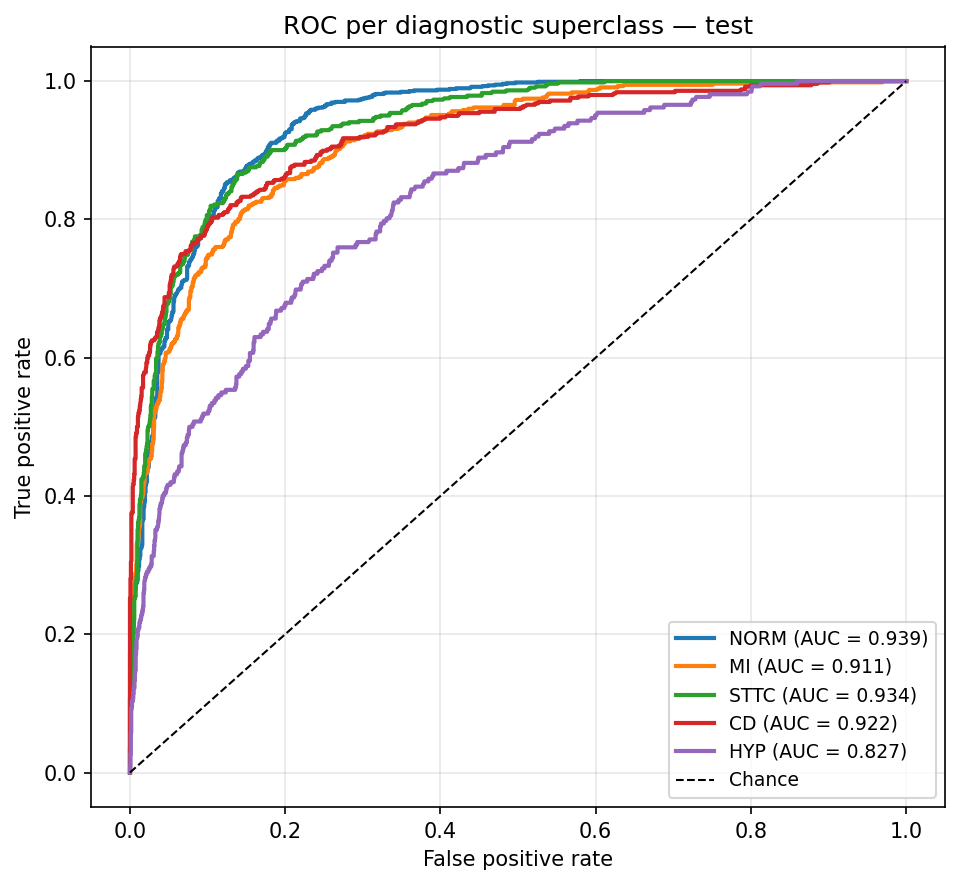

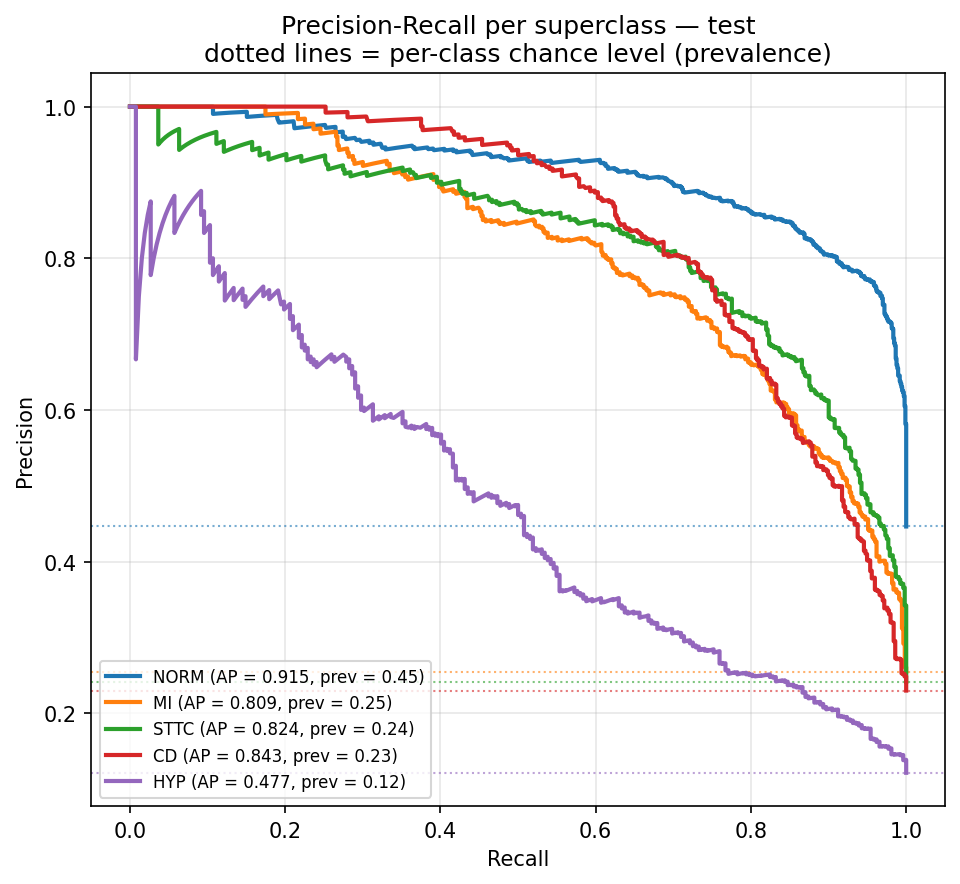

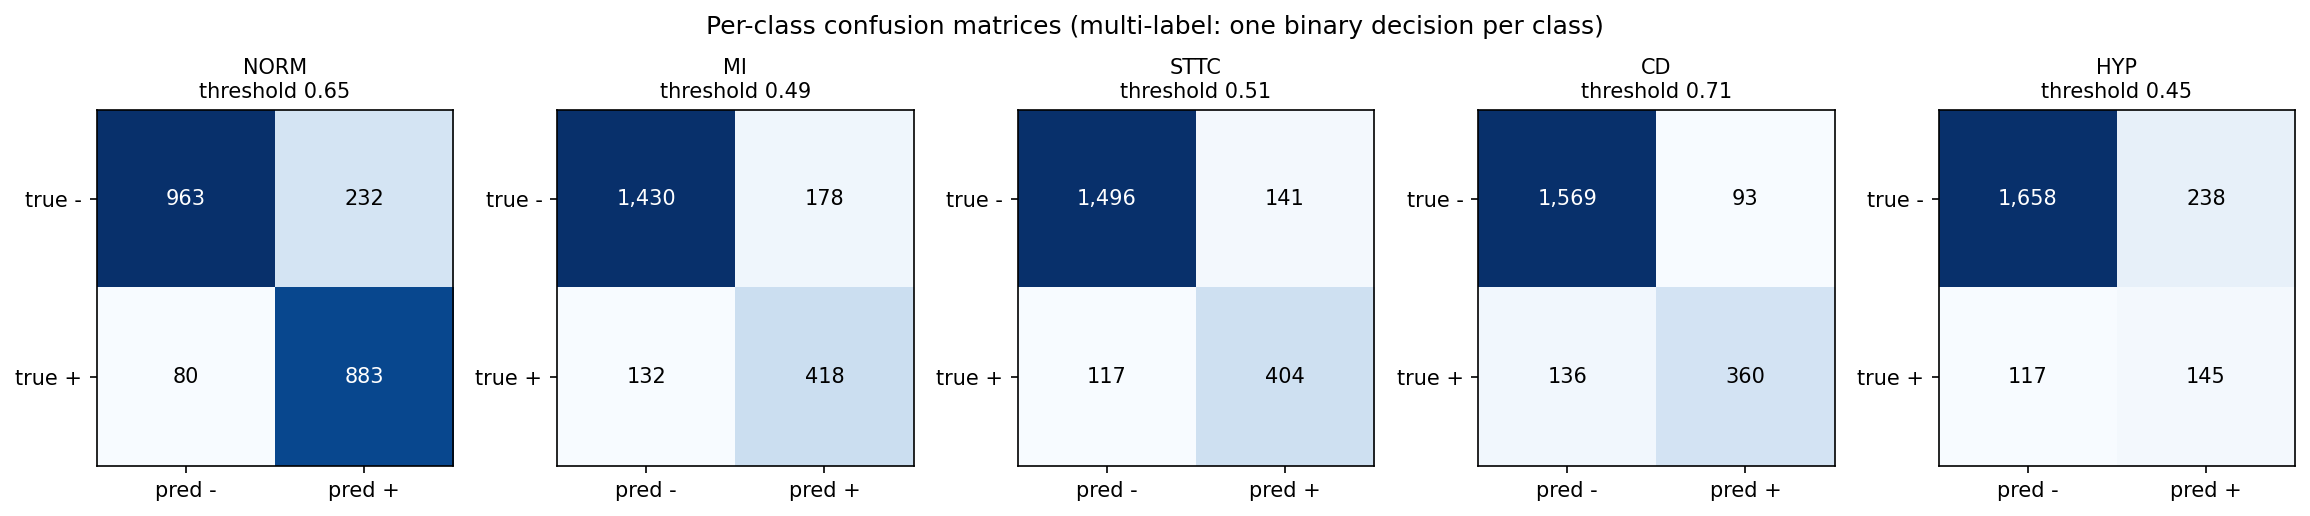

In [34]:
ev.plot_per_class_curves(test_true, test_prob, CLASSES, RESULTS, prefix="test")
ev.plot_per_class_confusion(test_true, test_prob, thresholds, CLASSES, RESULTS)

for name in ["roc_curve.png", "pr_curve.png", "confusion_matrix.png"]:
    display(Image(filename=str(RESULTS / name)))

In [35]:
# Does the deep model actually earn its complexity? The honest answer is
# sometimes no, and the code says so rather than burying it.
comparison = ev.build_comparison_table(experiments)
comparison.to_csv(RESULTS / "model_comparison.csv", index=False)
display(comparison)

recommendation = ev.recommend_model(experiments)
save_json(recommendation, RESULTS / "model_recommendation.json")
print(f"\nRECOMMENDED: {recommendation['recommended']}")
for reason in recommendation["reasoning"]:
    print("  -", reason)
if "warning" in recommendation:
    print("\nWARNING:", recommendation["warning"])

,model,macro_roc_auc,macro_pr_auc,macro_f1,micro_f1,exact_match,hamming_loss,parameters,train_seconds
0,statistical_baseline,0.8239,0.6029,0.6083,0.6507,0.4124,0.2062,660,3.08
1,cnn1d,0.9066,0.7741,0.7091,0.7512,0.5639,0.1357,371013,97.89


2026-09-29 09:35:11 | INFO     | cardiosense.ecg.evaluate     | RECOMMENDATION: keep cnn1d (macro_roc_auc = 0.9066)
2026-09-29 09:35:11 | INFO     | cardiosense.ecg.evaluate     |     cnn1d beats statistical_baseline by +0.0826 macro_roc_auc, above the 0.01 bar — the added complexity is justified.

RECOMMENDED: cnn1d
  - cnn1d beats statistical_baseline by +0.0826 macro_roc_auc, above the 0.01 bar — the added complexity is justified.


In [36]:
# Where did the CNN gain over the baseline, class by class?
# Prediction from section 8: most of the gain should land on STTC and MI,
# because those depend on temporal position, which global statistics discard.
if "statistical_baseline" in experiments:
    gains = pd.DataFrame({
        "baseline_auc": [metrics_baseline["per_class"][c].get("roc_auc") for c in CLASSES],
        "cnn_auc": [test_metrics["per_class"][c].get("roc_auc") for c in CLASSES],
    }, index=CLASSES)
    gains["gain"] = (gains.cnn_auc - gains.baseline_auc).round(4)
    display(gains.round(4).sort_values("gain", ascending=False))

,baseline_auc,cnn_auc,gain
MI,0.7769,0.9114,0.1345
CD,0.8394,0.9217,0.0822
HYP,0.7591,0.8275,0.0684
STTC,0.8662,0.9336,0.0674
NORM,0.8782,0.9389,0.0607


## 9b. Optional — ResNet-1D comparison (Experiment E-C)

The notebook already names this as the natural next lever ("Running the
ResNet-1D comparison" at the very end) once the CNN trains stably. It's
**optional and roughly doubles wall-clock time** — a second full training run
— so only run this cell if that budget is available.

It reuses the exact same evaluation path as the CNN (per-class thresholds
tuned on val, one test-set pass, added to the same `experiments` /
`comparison` / `recommend_model` machinery), so the comparison stays
apples-to-apples and honest — `recommend_model` applies a 0.01 macro-AUC bar
before it will actually recommend switching, which guards against reading
run-to-run seed noise as a real improvement.

In [37]:
# ============================================================
# OPTIONAL — E-C: ResNet-1D, compared against the CNN above
# Roughly doubles training time. Skip if you're not running this experiment.
# ============================================================
RUN_RESNET_COMPARISON = False  # flip to True to run E-C

if RUN_RESNET_COMPARISON:
    cfg_resnet = load_config("ecg")
    cfg_resnet.model["name"] = "resnet1d"
    cfg_resnet.training["num_workers"] = 0  # same worker-crash fix as §10

    model_resnet = build_model(cfg_resnet).to(device)

    loaders_resnet = build_dataloaders(waveforms, labels, splits, cfg_resnet)

    # same pos_weight — it's a property of the data/labels, not the model
    training_result_resnet = train_model(
        model_resnet, loaders_resnet, cfg_resnet, device,
        CHECKPOINTS / "resnet1d", pos_weight=pos_weight,
        experiment_name="resnet1d",
    )

    val_prob_r, val_true_r = ev.predict_probabilities(
        model_resnet, loaders_resnet["val"], device, use_amp
    )
    thresholds_r, threshold_info_r = ev.tune_per_class_thresholds(val_true_r, val_prob_r, cfg_resnet)

    test_prob_r, test_true_r = ev.predict_probabilities(
        model_resnet, loaders_resnet["test"], device, use_amp
    )
    test_metrics_r = ev.evaluate_multilabel(
        test_true_r, test_prob_r, thresholds_r, cfg_resnet, split_name="test/resnet1d"
    )

    experiments["resnet1d"] = {
        "metrics": test_metrics_r,
        "parameters": count_parameters(model_resnet),
        "train_seconds": training_result_resnet["total_seconds"],
    }

    comparison = ev.build_comparison_table(experiments)
    comparison.to_csv(RESULTS / "model_comparison.csv", index=False)
    display(comparison)

    recommendation = ev.recommend_model(experiments)
    save_json(recommendation, RESULTS / "model_recommendation.json")
    print(f"\nRECOMMENDED: {recommendation['recommended']}")
    for reason in recommendation["reasoning"]:
        print("  -", reason)
    if "warning" in recommendation:
        print("\nWARNING:", recommendation["warning"])
else:
    print("RUN_RESNET_COMPARISON is False — skipping E-C. Set it to True to run.")

RUN_RESNET_COMPARISON is False — skipping E-C. Set it to True to run.


## 14. Calibration — deliberately not done here

The clinical pipeline fits a calibrator; this one does not, and that is a
considered decision rather than an omission.

Multi-label calibration means five independent calibrators, each fitted on the
validation split, each needing enough positives to be stable. It is doable, but it
is a Phase 2 concern: the fusion stage is where calibrated ECG confidences will
actually be *used*, and doing it properly deserves its own evaluation rather than
being tacked on here.

So the ECG probabilities are **sigmoid outputs — ranking scores, not frequency
claims**, and `predict.py` says so in its output. Phase 2 must calibrate them
before using them as fusion weights.

## 15. Error Analysis

In [38]:
errors = ev.export_errors(
    splits["test"]["database"], test_true, test_prob, thresholds, CLASSES,
    RESULTS / "errors", prefix="test",
)

print(f"{errors['n_records_with_any_error']} of {errors['n_records']} records have "
      f"at least one class wrong (exact-match {errors['exact_match_rate']:.3f})")
pd.DataFrame(errors["per_class"]).T[["n_false_negative", "n_false_positive", "threshold"]]

2026-09-29 09:35:12 | INFO     | cardiosense.ecg.evaluate     | [test] 941 of 2158 records have at least one error (exact-match 0.564)
941 of 2158 records have at least one class wrong (exact-match 0.564)


,n_false_negative,n_false_positive,threshold
NORM,80,232,0.6502
MI,132,178,0.4877
STTC,117,141,0.5074
CD,136,93,0.7142
HYP,117,238,0.4532


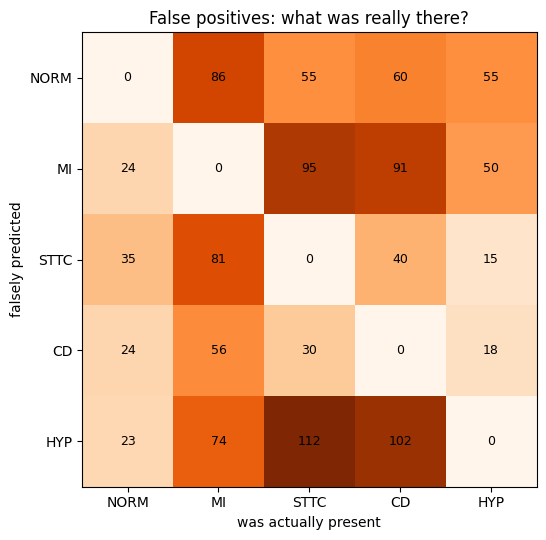

In [39]:
# Which class pairs get confused? For a multi-label task the interesting question
# is: when we falsely predict class A, which class was actually present?
predictions = (test_prob >= thresholds[None, :]).astype(int)
confusion = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
for predicted in range(len(CLASSES)):
    false_positive_rows = (predictions[:, predicted] == 1) & (test_true[:, predicted] == 0)
    for actual in range(len(CLASSES)):
        confusion[predicted, actual] = int(test_true[false_positive_rows, actual].sum())

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(confusion, cmap="Oranges")
ax.set_xticks(range(len(CLASSES)), CLASSES)
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_xlabel("was actually present")
ax.set_ylabel("falsely predicted")
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, confusion[i, j], ha="center", va="center", fontsize=9)
ax.set_title("False positives: what was really there?")
ax.grid(False)
plt.tight_layout()
plt.show()

## 13. Explainability — Integrated Gradients

**This is Integrated Gradients, and it is called that.** Neither architecture
contains an attention mechanism, so calling this "attention" would misdescribe the
model.

IG integrates the gradient along a straight path from a baseline (a flat trace) to
the actual signal. Its defining property is **completeness**: the attributions must
sum to `F(x) − F(baseline)`. The code checks this and automatically raises
`n_steps` when it fails, rather than returning a map that is known not to sum
correctly.

**Limitations, for the report:**
1. Attribution shows where the model was *sensitive*, not that a finding is present.
2. A different baseline redistributes the attributions; there is no uniquely correct choice.
3. Attributions are per-sample; the meaningful physiological unit is the beat.
4. Leads viewing overlapping territory (II/III/aVF) share credit arbitrarily.

In [40]:
ig_summary = run_ig_analysis(
    model, waveforms, splits["test"]["indices"], test_true, test_prob,
    thresholds, cfg, device, RESULTS / "explanations",
)

print(f"{ig_summary['n_explanations']} explanations written")
pd.DataFrame([
    {"record": r["record_id"], "class": r["class"], "case": r["case_type"],
     "p": r["probability"], "true": r["true_label"],
     "top_lead": r["top_leads"][0]["lead"],
     "peak_window_s": r["peak_window_seconds"]}
    for r in ig_summary["explanations"]
])

2026-09-29 09:35:15 | INFO     | cardiosense.ecg.explain      | Explained 1 records for class NORM (captum, 128 steps, converged=True, abs error 0.0238)
2026-09-29 09:35:16 | INFO     | cardiosense.ecg.explain      | Explained 1 records for class NORM (captum, 128 steps, converged=True, abs error 0.0341)
2026-09-29 09:35:18 | INFO     | cardiosense.ecg.explain      | Explained 1 records for class MI (captum, 128 steps, converged=True, abs error 0.0248)
2026-09-29 09:35:19 | INFO     | cardiosense.ecg.explain      | Explained 1 records for class MI (captum, 128 steps, converged=True, abs error 0.0273)
2026-09-29 09:35:20 | INFO     | cardiosense.ecg.explain      | Explained 1 records for class STTC (captum, 128 steps, converged=True, abs error 0.0110)
2026-09-29 09:35:21 | INFO     | cardiosense.ecg.explain      | Explained 1 records for class STTC (captum, 128 steps, converged=True, abs error 0.0379)
2026-09-29 09:35:22 | INFO     | cardiosense.ecg.explain      | Explained 1 records fo

,record,class,case,p,true,top_lead,peak_window_s
0,2047,NORM,TP,0.9940,1,aVR,"[1.22, 2.22]"
1,17346,NORM,FN,0.0536,1,V1,"[8.84, 9.84]"
2,17713,MI,TP,0.9989,1,V2,"[8.66, 9.66]"
3,7765,MI,FN,0.0058,1,aVF,"[8.86, 9.86]"
4,8945,STTC,TP,0.9879,1,V1,"[4.21, 5.21]"
5,1242,STTC,FN,0.0210,1,aVR,"[4.67, 5.67]"
6,11971,CD,TP,0.9999,1,II,"[2.75, 3.75]"
7,20588,CD,FN,0.0434,1,II,"[6.34, 7.34]"
8,9708,HYP,TP,0.9722,1,aVR,"[1.48, 2.48]"
9,9146,HYP,FN,0.0475,1,aVR,"[0.03, 1.03]"


--- TP: class NORM, p = 0.994, true = 1 ---


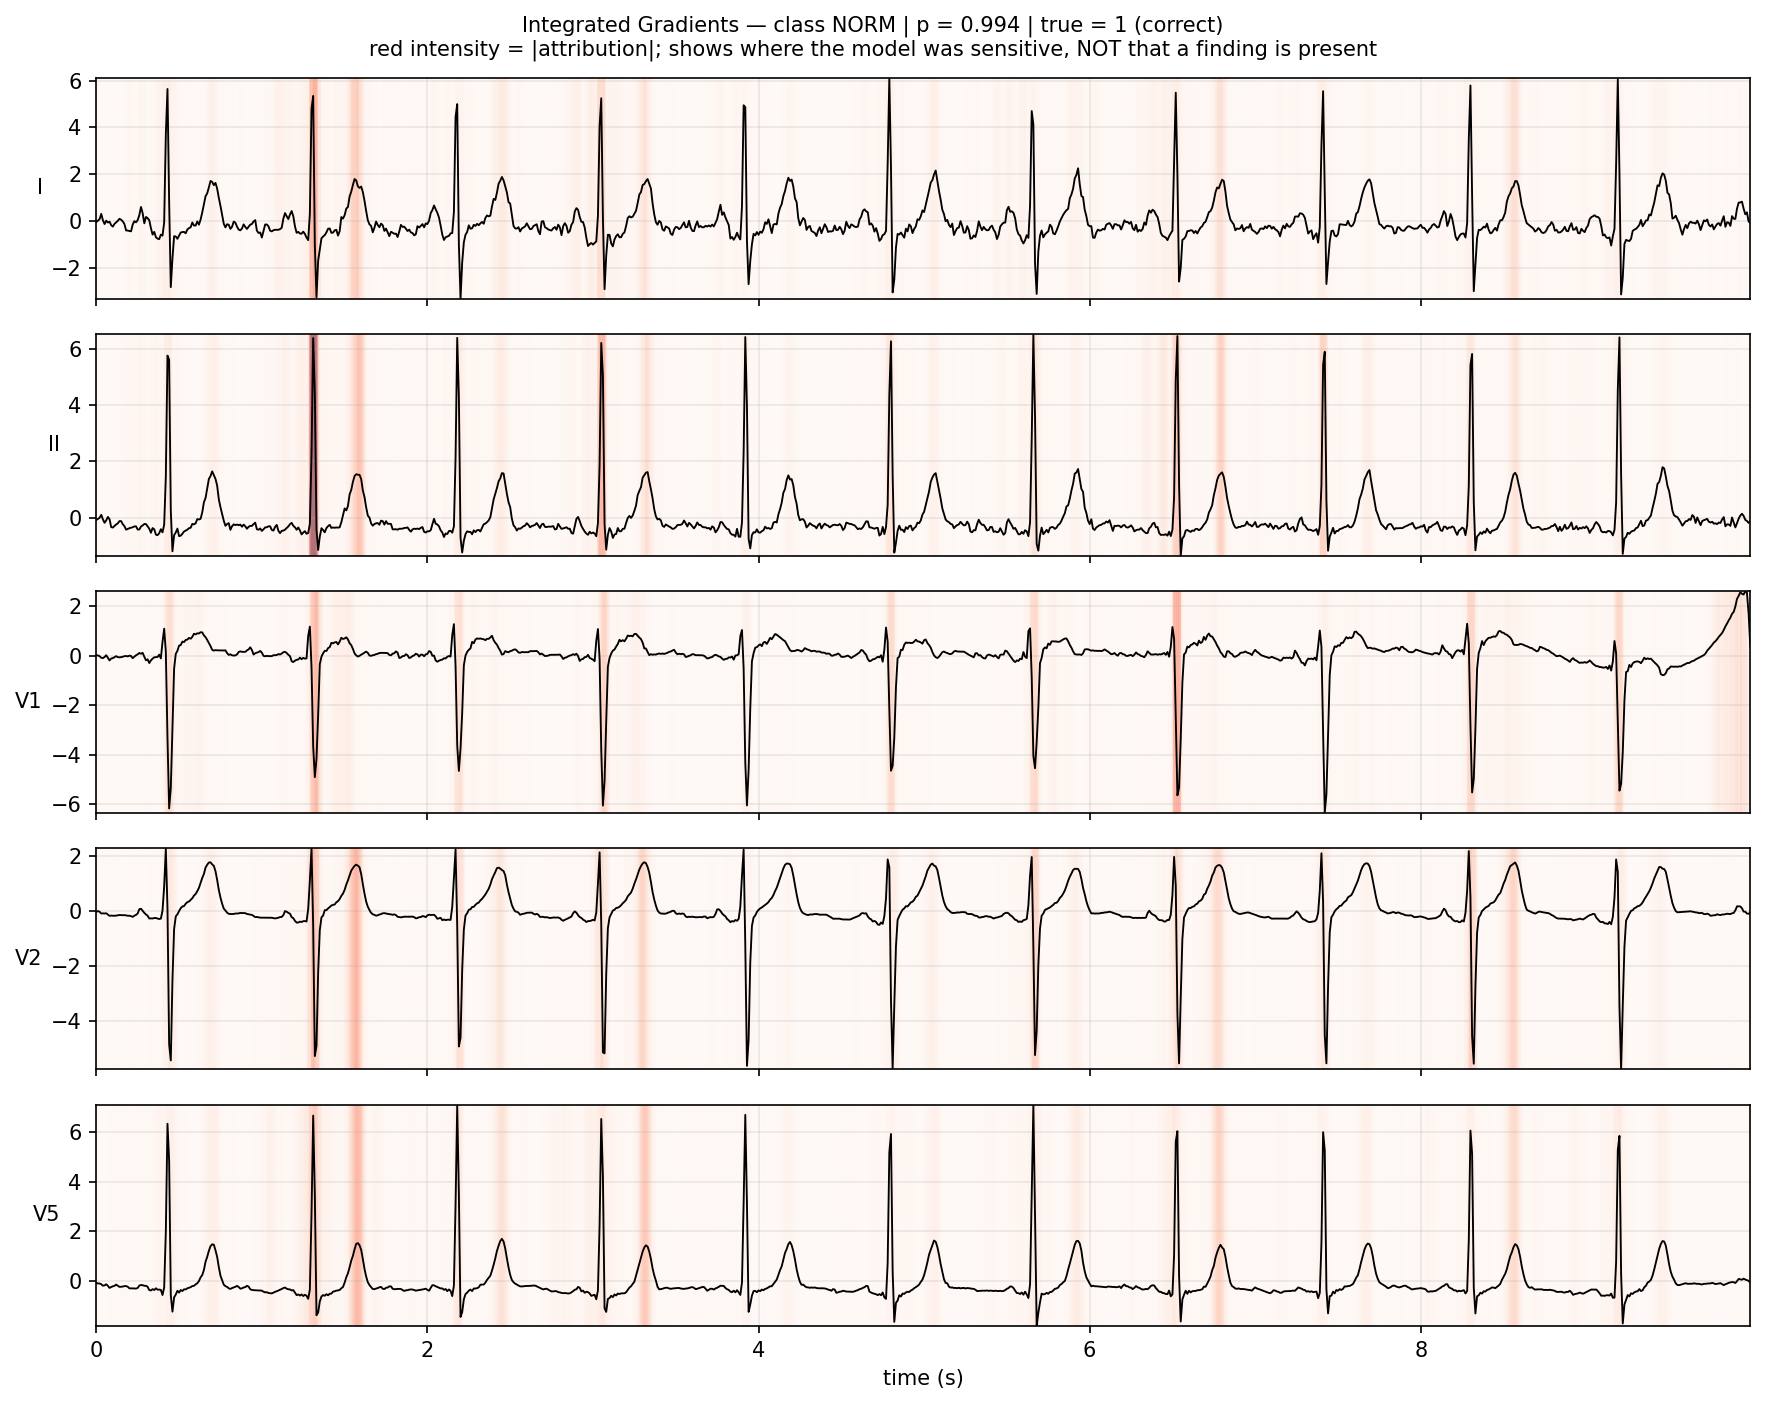

--- FN: class NORM, p = 0.0536, true = 1 ---


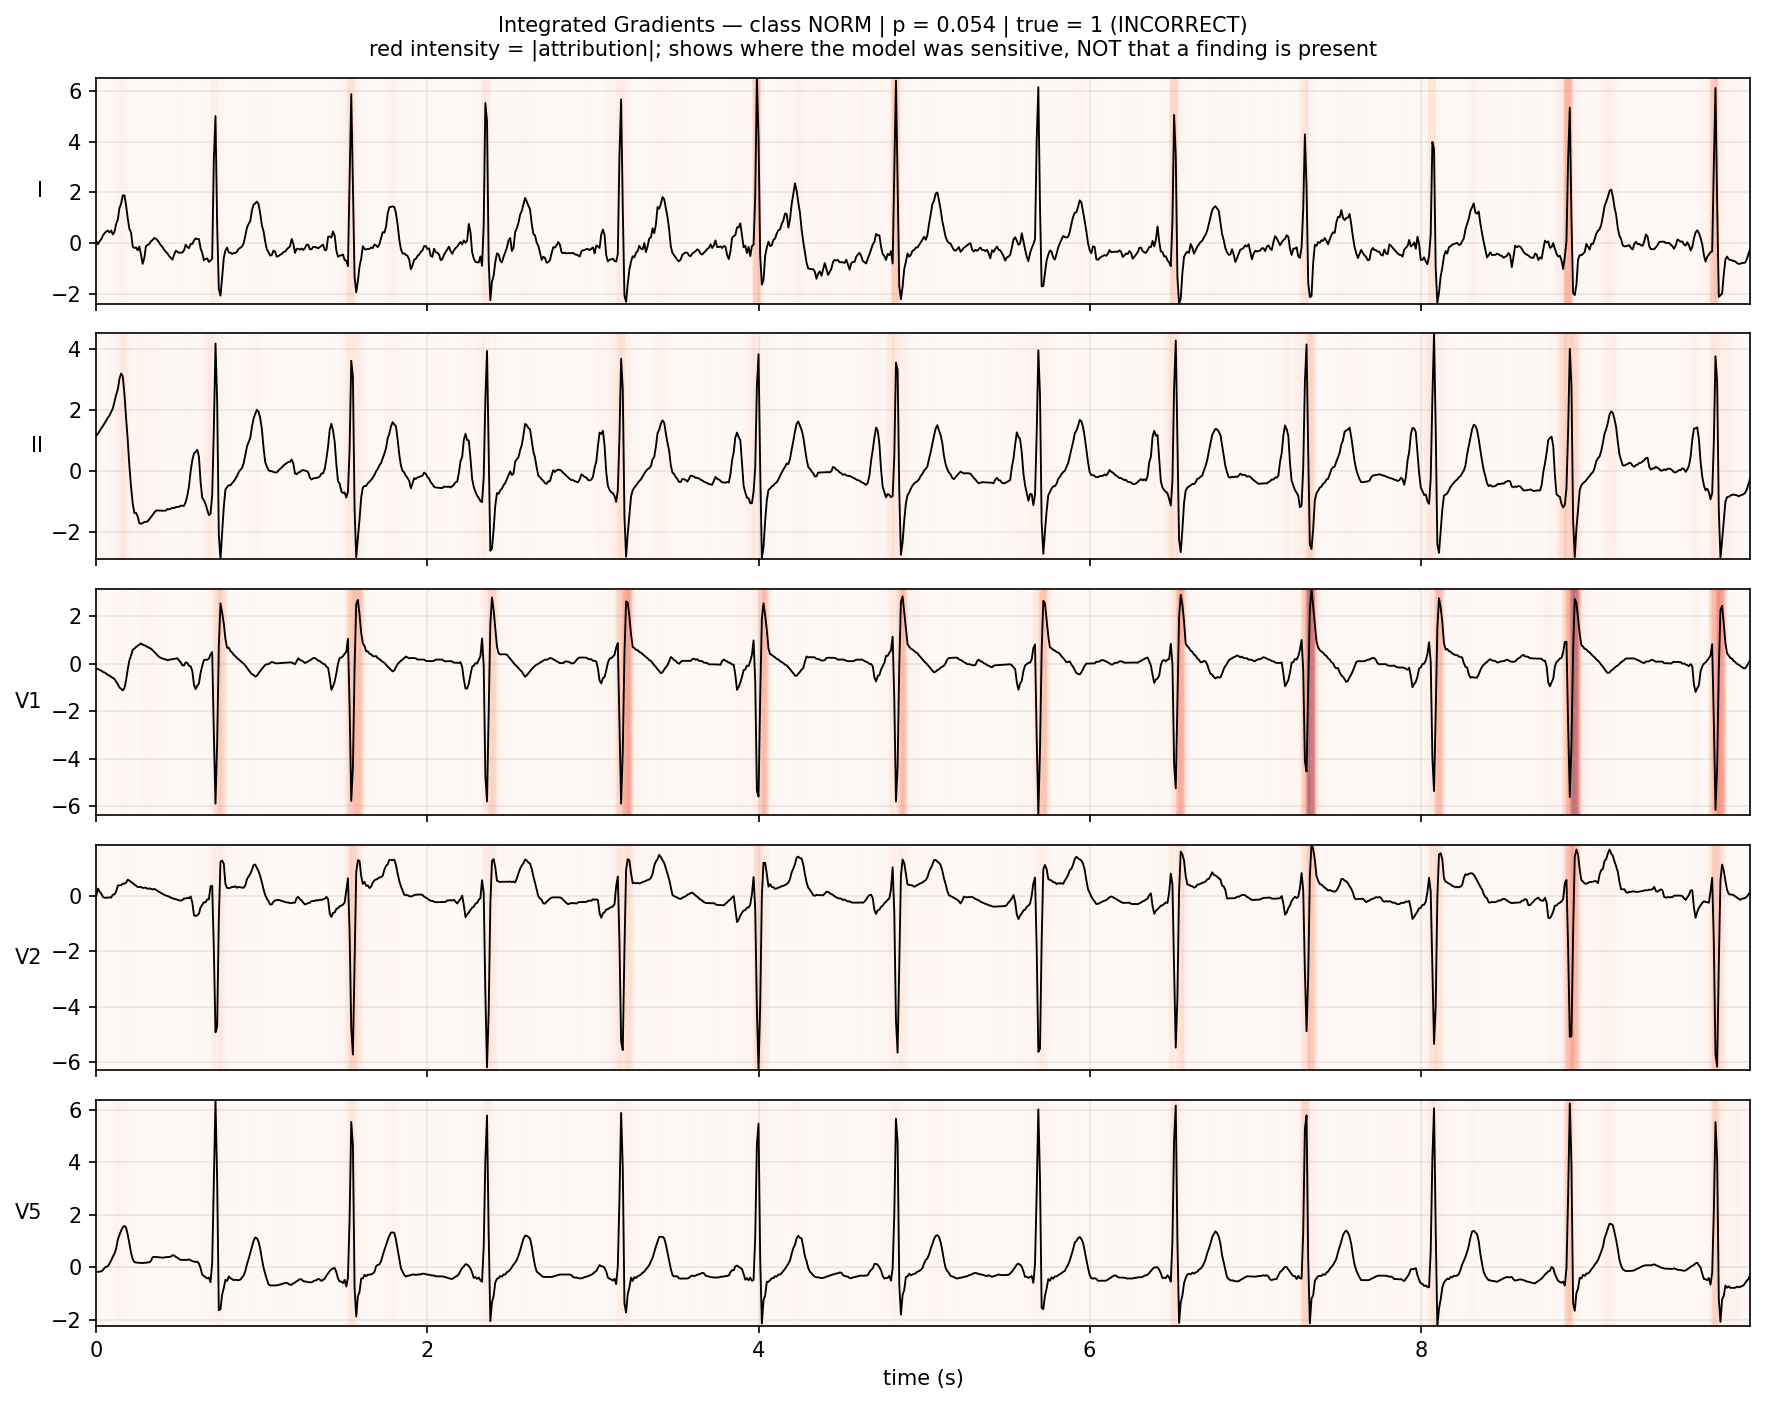

In [41]:
# Show a true positive and a false negative side by side. The false negative is
# the informative one: where did the model look when it MISSED the finding?
for case_type in ("TP", "FN"):
    for record in ig_summary["explanations"]:
        if record["case_type"] == case_type:
            print(f"--- {case_type}: class {record['class']}, p = {record['probability']}, "
                  f"true = {record['true_label']} ---")
            display(Image(filename=str(RESULTS / "explanations" / record["figure"])))
            break

## 16. Save Model

In [42]:
model_path = MODELS / cfg.output.model_file
torch.save({
    "model_state": model.state_dict(),
    "model_name": str(cfg.model.name),
    "class_names": CLASSES,
    "thresholds": thresholds.tolist(),
}, model_path)

inference_config = {
    "model_version": str(cfg.output.model_version),
    "model_name": str(cfg.model.name),
    "model_params": cfg.model.get(str(cfg.model.name), {}).to_dict(),
    "classes": CLASSES,
    "label_mapping": {str(i): name for i, name in enumerate(CLASSES)},
    "thresholds": {name: round(float(t), 4) for name, t in zip(CLASSES, thresholds)},
    "task_type": str(cfg.task.type),
    "sampling_rate": int(cfg.dataset.sampling_rate),
    "signal_length": int(cfg.dataset.signal_length),
    "n_leads": int(cfg.dataset.n_leads),
    "lead_names": list(cfg.dataset.lead_names),
    "preprocessing": cfg.preprocessing.to_dict(),
}
config_path = save_json(inference_config, MODELS / cfg.output.config_file)

metadata_path = save_json({
    **inference_config,
    "created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
    "modality": "ecg",
    "dataset": {"name": str(cfg.dataset.name), "version": str(cfg.dataset.version)},
    "architecture": architecture,
    "split_summary": split_summary,
    "label_report": label_report,
    "training": training_result,
    "test_metrics": test_metrics,
    "threshold_info": threshold_info,
    "recommendation": recommendation,
    "training_config": cfg.to_dict(),
}, MODELS / cfg.output.metadata_file)

for path in (model_path, config_path, metadata_path):
    print(f"  {path.name:<28} {path.stat().st_size / 1024:>9.1f} KB")

  ecg_model.pth                   1463.8 KB
  ecg_config.json                    1.2 KB
  ecg_metadata.json                 17.7 KB


## 17. Save Results

In [43]:
save_json({
    "model": str(cfg.model.name),
    "test": test_metrics,
    "model_comparison": comparison.to_dict(orient="records"),
    "recommendation": recommendation,
    "split": split_summary,
    "thresholds": threshold_info,
    "training": training_result,
}, RESULTS / "metrics.json")

with ExperimentTracker("ecg_notebook", modality="ecg", config=cfg,
                       primary_metric="macro_roc_auc") as run:
    run.log_params({
        "model": str(cfg.model.name),
        "batch_size": int(cfg.training.batch_size),
        "learning_rate": float(cfg.training.learning_rate),
        "epochs": int(cfg.training.epochs),
        "parameters": architecture["total"],
        "n_train": split_summary["train"]["n_records"],
    })
    run.log_metrics({k: v for k, v in test_metrics.items() if isinstance(v, (int, float))},
                    split="test")
    run.log_history(training_result["history"])
    run.set_best_epoch(int(training_result["best_epoch"]))
    run.log_artifact("model", model_path)

print("\nfiles written:")
for path in sorted(RESULTS.rglob("*")):
    if path.is_file():
        print("  ", path.relative_to(RESULTS))

2026-09-29 09:35:26 | INFO     | cardiosense.common.experiment | Experiment started: 20260929_093526__ecg__ecg_notebook
2026-09-29 09:35:26 | INFO     | cardiosense.common.experiment | Experiment completed in 0.0s: 20260929_093526__ecg__ecg_notebook

files written:
   class_distribution.png
   confusion_matrix.png
   dataset_description.json
   errors/test_error_summary.json
   errors/test_errors.csv
   errors/test_predictions.csv
   explanations/.gitkeep
   explanations/ig_FN_CD_record20588.png
   explanations/ig_FN_HYP_record9146.png
   explanations/ig_FN_MI_record7765.png
   explanations/ig_FN_NORM_record17346.png
   explanations/ig_FN_STTC_record1242.png
   explanations/ig_TP_CD_record11971.png
   explanations/ig_TP_HYP_record9708.png
   explanations/ig_TP_MI_record17713.png
   explanations/ig_TP_NORM_record2047.png
   explanations/ig_TP_STTC_record8945.png
   explanations/ig_summary.json
   label_report.json
   metrics.json
   model_comparison.csv
   model_recommendation.json
   p

## 18. Example Inference

Loads the saved artifacts from scratch and runs on a raw WFDB record, the way a
Phase 2 caller would.

Note the output shape: **several classes can be positive at once**. It is
deliberately not collapsed into a single diagnosis.

In [44]:
predictor = ECGPredictor.load()

test_record = splits["test"]["database"].iloc[0]
record_path = root / test_record.filename_lr

result = predictor.predict_record(record_path)
print(json.dumps({k: v for k, v in result.items() if k != "notes"}, indent=2))

actual = {c: int(splits["test"]["labels"][0, i]) for i, c in enumerate(CLASSES)}
print("\nactual labels:", actual)
print("predicted    :", result["predictions"])

{
  "predictions": {
    "NORM": 1,
    "MI": 0,
    "STTC": 0,
    "CD": 0,
    "HYP": 0
  },
  "probabilities": {
    "NORM": 0.9724,
    "MI": 0.013,
    "STTC": 0.0091,
    "CD": 0.0957,
    "HYP": 0.0291
  },
  "positive_classes": [
    "NORM"
  ],
  "top_class": "NORM",
  "top_probability": 0.9724,
  "thresholds": {
    "NORM": 0.6502,
    "MI": 0.4877,
    "STTC": 0.5074,
    "CD": 0.7142,
    "HYP": 0.4532
  },
  "model": "cnn1d",
  "model_version": "ecg-v0.1.0",
  "modality": "ecg",
  "task_type": "multilabel",
  "source": {
    "record": "/content/drive/MyDrive/CardioSense/data/ecg/ptbxl/records100/00000/00009_lr",
    "sampling_rate": 100,
    "leads": [
      "I",
      "II",
      "III",
      "AVR",
      "AVL",
      "AVF",
      "V1",
      "V2",
      "V3",
      "V4",
      "V5",
      "V6"
    ]
  }
}

actual labels: {'NORM': 1, 'MI': 0, 'STTC': 0, 'CD': 0, 'HYP': 0}
predicted    : {'NORM': 1, 'MI': 0, 'STTC': 0, 'CD': 0, 'HYP': 0}


## Phase 1 ECG checklist

| Item | Where |
|---|---|
| PTB-XL verified | §4 |
| Classification task selected & justified | §3, top of notebook, `docs/datasets.md` |
| Signal preprocessing | §6 — each step justified individually |
| Leakage-free split | §7 — official `strat_fold`, patient disjointness asserted |
| Baseline | §8 (E-A) |
| 1D CNN | §9–10 (E-B) |
| ResNet-1D if justified | `--set model.name=resnet1d` (E-C) |
| Evaluation | §12 — multi-label metrics, no "accuracy" |
| Error analysis | §15 |
| Explainability | §13 — Integrated Gradients, completeness-checked |
| Saved model | §16 |
| Inference script | §18 · `src/cardiosense/ecg/predict.py` |

### Running the ResNet-1D comparison (E-C)

Only worth doing once the CNN trains stably:

```bash
python -m cardiosense.ecg.train --set model.name=resnet1d --experiment-name ecg_resnet
```

Then compare against the CNN. `ev.recommend_model` applies a 0.01 macro-AUC bar —
below that, run-to-run seed variation explains the difference, and the honest
recommendation is to keep the simpler CNN.

**Next:** `03_xray_training.ipynb`.

Headless equivalent of this notebook:

```bash
python -m cardiosense.ecg.train
```

*Research artifact. Not a medical device. Not for clinical use.*